# 🛡️ Blended Defence — BaEraser-lite (Machine Unlearning)

**Attack:** Blended (Chen et al., 2017) — `x' = (1-α)·x + α·k`, `α=0.1`, target class 0  
**Defence:** `baeraser_lite.py` (shared core for BadNets / Blended / Silent Killer) — Generator+MINE recovery → exact-candidate selection → dynamic-penalty unlearning  
**Model:** ResNet-18 (CIFAR-stem) · **Dataset:** CIFAR-10 · **Seed:** 2027

This notebook **imports `baeraser_lite.py`** (it does not re-implement it). Per-attack budgets come from
`ATTACK_RECOVERY_CONFIG['blended']` (coarse ε = 0.2/0.5/0.8, fine ε fallback, 6 epochs, 24 candidates, early exit at 2 accepted).

| What the defender is told | Value |
|---|---|
| Trigger family | blend |
| α | `0.1` (= `ALPHA_TRAIN`, required constructor arg) |
| Trigger shape | `3×32×32` = 3,072 values |
| The actual key `k` (`blended_pattern_seed777.npy`) | **NOT given** — post-hoc evaluation only |

> ⚠️ **`BlendedTriggerOperator.apply` in the current `baeraser_lite.py` mixes colour spaces** (blends a raw-[0,1] key into
> *normalized* images). Cell D1 demonstrates this against `add_blended_trigger_global` and uses a one-method corrected
> subclass. Patch the file too (diff shown in the chat reply) before reusing it for other notebooks.
>
> **Reporting rule:** `oracle_trigger` is never used here. 0 accepted triggers, or accepted triggers that don't cut ASR, are
> logged as failure cases.

> ## ⚠️ Protocol v3 (this notebook was updated — read before running)
>
> | Change | Why |
> |---|---|
> | **Evaluation split**: defense budget = 2,000 + select slice = 500, both from the **val half of the CIFAR-10 test set**; CA/ASR on the **report half only** (same split, same `baeraser_lite.split_test_set` / `make_select_split` as the FT/ANP/NAD notebook; hash cross-checked) | the poisoned checkpoints saw all 50k train images, so the old defense images (from train) overlapped them |
> | **Checkpoint selection is non-oracle**: held-out CA floor → proxy ASR → (optional) ASR of *freshly recovered* triggers (`FRESH_SELECT_K`). **No early stop.** Headline = real CA/ASR at the selected epoch; the best-real-ASR epoch is shown separately as an *oracle upper bound* | v2 selected on test CA/ASR, and the proxy ASR can be gamed |
> | **No warm start, no chaining**: every ε starts from a fresh random init (hashes logged, `fresh_init_verified` asserted) | v2 silently carried G/MINE weights from one ε (and one poison rate) to the next |
> | **Target-class images excluded** from the recovery hinge and the unlearning triggered batches | they satisfy the target objective trivially |
> | **Audits**: fresh-recovery audit + fresh universal-perturbation audit on poisoned / sanitized (/ clean) models; optional **clean-model control** (`CLEAN_CKPT_PATH`) | to separate backdoor removal from generic adversarial robustness |
> | Outputs go to `baeraser_blended_v3/` | never mix with v1/v2 files |
>
> **Smoke test first**: `ACTIVE_TAGS = ['pr01']` (cell A2). Inspect, then set `['pr01','pr05','pr10']` and re-run from cell B2 onward.
> **Saved cell outputs in this file are from the old protocol until you re-run.**
> Still true: the defender is told the blend family and α (disclose this); `oracle_trigger` is never used.
>
> ### v3.1 changes
> * **Select-slice CA gate is tightened by `CA_SELECT_MARGIN`** (default 0.01 = 1pp; a 500-image slice has ≈1pp noise, so a 5pp gate on it let the ANP run in the FT/ANP/NAD notebook lose 5.9pp on the report half). The report-half CA drop is flagged in the master table (`CA_drop_exceeds_tolerance`). Set `CA_SELECT_MARGIN = 0` to reproduce the un-tightened gate.
> * **New cell I4**: per-class accuracy + clean-image airplane-prediction rate for baseline vs sanitized (is a ~0% ASR just "stopped predicting airplane"?).
> * File hashes are pinned (`ENFORCE_FILE_HASH`); the executed FT/ANP/NAD notebook showed repo files whose hashes differ from the delivered ones, so re-copy `baeraser_lite.py`/`nad.py` (or paste the printed hash).
> * Shared-root safe split file (compared, never overwritten) and the same `ps-capstone2` cross-check as the FT/ANP/NAD notebook.


---
## Section A — Setup

In [1]:
# ════════════════════════════════════════════════════════════════════════
# Cell A1 — Drive Mount, Repository, Dependencies
# ════════════════════════════════════════════════════════════════════════
import os, sys, shutil

from google.colab import drive
drive.mount('/content/drive')

REPO_NAME = 'adaptive-backdoor-defense'
REPO_URL  = 'https://github.com/Aritraghoshdastidar/adaptive-backdoor-defense.git'

if os.path.isdir(f'/content/{REPO_NAME}'):
    print(f'Repository already present at /content/{REPO_NAME}')
elif os.path.isdir(f'/content/drive/MyDrive/{REPO_NAME}'):
    os.symlink(f'/content/drive/MyDrive/{REPO_NAME}', f'/content/{REPO_NAME}')
    print('Symlinked from Drive.')
else:
    print(f'Cloning {REPO_URL} ...')
    !git clone {REPO_URL}

%cd /content/{REPO_NAME}

for _f in ['core/models.py', 'core/metrics.py', 'core/data_utils.py',
           'core/attacks.py', 'core/detection.py']:
    assert os.path.isfile(_f), f'MISSING: {_f}'
print('All core project modules found.')

import torch
print(f'Python:  {sys.version}')
print(f'PyTorch: {torch.__version__}')
print(f'CUDA:    {torch.cuda.is_available()} — '
      f'{torch.cuda.get_device_name(0) if torch.cuda.is_available() else "N/A"}')

Mounted at /content/drive
Cloning https://github.com/Aritraghoshdastidar/adaptive-backdoor-defense.git ...
Cloning into 'adaptive-backdoor-defense'...
remote: Enumerating objects: 350, done.
remote: Counting objects: 100% (71/71), done.
remote: Compressing objects: 100% (61/61), done.
remote: Total 350 (delta 28), reused 26 (delta 8), pack-reused 279 (from 2)
Receiving objects: 100% (350/350), 168.74 MiB | 16.55 MiB/s, done.
Resolving deltas: 100% (116/116), done.
/content/adaptive-backdoor-defense
All core project modules found.
Python:  3.13.15 (main, Aug  6 2026, 11:06:22) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
CUDA:    True — Tesla T4


In [2]:
# ════════════════════════════════════════════════════════════════════════
# Cell A2 — Constants & Paths   (BaEraser hyper-parameters now live in baeraser_lite.py)
# ════════════════════════════════════════════════════════════════════════
import torch, numpy as np, random, os, time, copy, json, math, gc, shutil, sys
import torch.nn as nn
import torch.nn.functional as F
import torchvision.transforms as transforms
from torch.utils.data import DataLoader
import pandas as pd
import matplotlib.pyplot as plt

ATTACK_NAME  = 'Blended'
SEED         = 2027
TARGET_CLASS = 0
BATCH_SIZE   = 128
POISON_RATES = [0.01, 0.05, 0.10]
ALL_PR_TAGS  = ['pr01', 'pr05', 'pr10']
ACTIVE_TAGS  = ['pr01', 'pr05', 'pr10']          # SMOKE TEST = pr01 only. Full run: ['pr01', 'pr05', 'pr10']
PR_TAGS      = [t for t in ALL_PR_TAGS if t in ACTIVE_TAGS]
PR_MAP       = {'pr01': 0.01, 'pr05': 0.05, 'pr10': 0.10}
ALPHA_TRAIN  = 0.1
ALPHA_TEST   = 0.1
IMG_SHAPE    = (3, 32, 32)
CIFAR_MEAN   = (0.4914, 0.4822, 0.4465)
CIFAR_STD    = (0.2470, 0.2435, 0.2616)

WARM_START = False     # MUST stay False (v3): fresh random init per epsilon and per poison rate, no chaining.
assert not WARM_START, 'WARM_START must be False under protocol v3'

# ── Protocol v3 ───────────────────────────────────────────────────────────
PROTOCOL     = 'heldout_test_split'   # or 'legacy_train_indices' (old, overlapping, leaky; comparison only)
N_VAL        = 2500                   # val half of the TEST set: defense budget + select slice
N_SELECT     = 500                    # of those: held-out select slice
SPLIT_SEED   = 2027
EXPECTED_BASELINE_CA = {'pr01': 0.9483, 'pr05': 0.9473, 'pr10': 0.9439}   # recorded CA on the FULL test set
BASELINE_CA_TOL      = 0.001
FRESH_SELECT_K  = 1       # 1 = smoke test (proxy only). 3 = re-rank top-3 epochs by fresh-trigger ASR
RUN_FRESH_AUDIT = True    # fresh recovery + fresh UAP on poisoned / sanitized models
CLEAN_CKPT_PATH = None    # e.g. f'{DRIVE_ROOT}/resnet18_clean.pth' -> runs the clean-model control; None = skipped
BL_PY_SHA256    = None    # Skip sha256 check of baeraser_lite.py
ENFORCE_FILE_HASH = False   # Skip all file hash enforcements
CA_SELECT_MARGIN  = 0.01   # v3.1: select-slice CA gate = CA_DROP_TOLERANCE - margin (500-image slice ~ 1pp noise); 0 = old behaviour

def set_seed(seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed); random.seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark     = False

set_seed(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

DRIVE_ROOT   = '/content/drive/MyDrive/ps-capstone2'
PATTERN_PATH = f'{DRIVE_ROOT}/blended_pattern_seed777.npy'

BAERASER_DIR             = f'{DRIVE_ROOT}/baeraser_blended_v3'	 # v3: separate from v1/v2 outputs
BAERASER_CKPT_DIR        = f'{BAERASER_DIR}/checkpoints'
BAERASER_TRIGGER_DIR     = f'{BAERASER_DIR}/triggers'
BAERASER_TRIGGER_FIG_DIR = f'{BAERASER_DIR}/trigger_figures'
BAERASER_LOG_DIR         = f'{BAERASER_DIR}/logs'
BAERASER_FIG_DIR         = f'{BAERASER_DIR}/figures'
BAERASER_CSV_DIR         = f'{BAERASER_DIR}/csv'
STRIP_DIR                = f'{BAERASER_DIR}/strip'
GRADCAM_DIR              = f'{BAERASER_DIR}/gradcam'
for _d in [BAERASER_DIR, BAERASER_CKPT_DIR, BAERASER_TRIGGER_DIR, BAERASER_TRIGGER_FIG_DIR,
           BAERASER_LOG_DIR, BAERASER_FIG_DIR, BAERASER_CSV_DIR, STRIP_DIR, GRADCAM_DIR]:
    os.makedirs(_d, exist_ok=True)
print(f'DEVICE={DEVICE} SEED={SEED} ATTACK={ATTACK_NAME} ALPHA_TRAIN={ALPHA_TRAIN} ALPHA_TEST={ALPHA_TEST} WARM_START={WARM_START} PROTOCOL={PROTOCOL} ACTIVE={PR_TAGS}')

DEVICE=cuda SEED=2027 ATTACK=Blended ALPHA_TRAIN=0.1 ALPHA_TEST=0.1 WARM_START=False PROTOCOL=heldout_test_split ACTIVE=['pr01', 'pr05', 'pr10']


In [3]:
# ════════════════════════════════════════════════════════════════════════
# Cell A3 — Project imports + baeraser_lite
# ════════════════════════════════════════════════════════════════════════
from core.models     import get_resnet18
from core.metrics    import calculate_ca, calculate_asr
from core.data_utils import load_cifar10, CIFARPoisoned
from core.attacks    import add_blended_trigger_global
from core.detection  import run_strip, plot_strip_results

import importlib, hashlib, inspect, subprocess
try:                              # pick up pushed updates (harmless if the tree is dirty / offline)
    _r = subprocess.run(['git', '-C', os.getcwd(), 'pull', '--ff-only'], capture_output=True, text=True, timeout=60)
    print('git pull:', (_r.stdout.strip() or _r.stderr.strip())[:200])
except Exception as e:
    print(f'git pull skipped ({e})')
import defenses.baeraser_lite as BL
importlib.reload(BL)            # picks up edits to the .py without restarting the runtime

# ── v3: verify the EXACT file + API this notebook was written for ─────────────
_bl_sha = hashlib.sha256(open(BL.__file__, 'rb').read()).hexdigest()
print(f'baeraser_lite.py: {BL.__file__}\n  sha256: {_bl_sha}')
if BL_PY_SHA256 is not None and _bl_sha != BL_PY_SHA256 and not ENFORCE_FILE_HASH:
    print(f'  ⚠️  baeraser_lite.py differs from the delivered v3 file (sha {_bl_sha[:16]}…) — continuing because ENFORCE_FILE_HASH=False')
elif BL_PY_SHA256 is not None and _bl_sha != BL_PY_SHA256:
    raise RuntimeError(f'baeraser_lite.py is NOT the expected v3 file.\n  expected {BL_PY_SHA256}\n  found    {_bl_sha}\n'
                       f'Copy the updated file into defenses/ (and push), or set BL_PY_SHA256=None to skip.')
for _fn in ['split_test_set', 'make_select_split', 'assert_baseline_ca', 'fresh_recovery_audit',
            'universal_adv_vulnerability', 'summarize_result', 'state_hash']:
    assert hasattr(BL, _fn), f'baeraser_lite.{_fn} missing: old file?'
assert {'fresh_select_k', 'select_loader', 'exclude_target', 'allow_leaky_selection'} <= \
       set(inspect.signature(BL.baeraser_unlearning).parameters), 'baeraser_unlearning signature is not v3'
assert {'heldout_loader', 'chain_epsilons', 'return_states'} <= \
       set(inspect.signature(BL.recover_trigger_pool).parameters), 'recover_trigger_pool signature is not v3'
assert tuple(BL.CIFAR_STD) == tuple(CIFAR_STD) and tuple(BL.CIFAR_MEAN) == tuple(CIFAR_MEAN), 'normalisation mismatch'
print('baeraser_lite v3 API verified ✓')

BAERASER_RECOVERY_ASR_THRESHOLD = BL.BAERASER_RECOVERY_ASR_THRESHOLD
_cfg = BL.ATTACK_RECOVERY_CONFIG['blended']
print('Recovery budget (blended):', _cfg)
print(f'Unlearning: α={BL.BAERASER_ALPHA} β={BL.BAERASER_BETA} lr={BL.BAERASER_UNLEARN_LR} '
      f'max_ep={BL.BAERASER_MAX_UNLEARNING_EPOCHS} CA tol={BL.CA_DROP_TOLERANCE} '
      f'accept≥{BAERASER_RECOVERY_ASR_THRESHOLD}')

_m = get_resnet18(); assert _m(torch.randn(1, 3, 32, 32)).shape == (1, 10); del _m
print('All imports verified.')

git pull: Already up to date.
baeraser_lite.py: /content/adaptive-backdoor-defense/defenses/baeraser_lite.py
  sha256: 7f2b6269414a2835649746442253c7d68a37b2f9d7499a99105ad189c62b68f0
baeraser_lite v3 API verified ✓
Recovery budget (blended): {'epsilons': [0.2, 0.5, 0.8], 'fine_epsilons': [0.35, 0.65, 0.95, 0.05], 'epochs': 6, 'n_candidates': 24, 'min_accepted_to_stop': 2}
Unlearning: α=1.0 β=1.0 lr=0.0001 max_ep=15 CA tol=0.05 accept≥0.8
All imports verified.


---
## Section B — Dataset, Shared Indices, Blend Pattern (evaluation only)

In [4]:
# ════════════════════════════════════════════════════════════════════════
# Cell B1 — Load CIFAR-10 + Transforms   (defence transform is DETERMINISTIC)
# ════════════════════════════════════════════════════════════════════════
import shutil
CIFAR_LOCAL_ROOT  = './data'
CIFAR_DRIVE_CACHE = f'{DRIVE_ROOT}/cifar10_cache'

_local = os.path.join(CIFAR_LOCAL_ROOT, 'cifar-10-batches-py')
if not os.path.exists(_local):
    if os.path.exists(os.path.join(CIFAR_DRIVE_CACHE, 'cifar-10-batches-py')):
        print('Copying CIFAR-10 from Drive cache...')
        os.makedirs(CIFAR_LOCAL_ROOT, exist_ok=True)
        shutil.copytree(os.path.join(CIFAR_DRIVE_CACHE, 'cifar-10-batches-py'), _local)
    else:
        print('Will download CIFAR-10.')
else:
    print('Local CIFAR-10 already present.')

transform_test = transforms.Compose([transforms.ToTensor(),
                                     transforms.Normalize(CIFAR_MEAN, CIFAR_STD)])
transform_defense = transform_test      # deterministic — no crop / flip

raw_trainset = load_cifar10(train=True,  transform=None)
data         = raw_trainset.data.copy()
labels       = np.array(raw_trainset.targets).copy()

testset     = load_cifar10(train=False, transform=transform_test)
testloader  = DataLoader(testset, batch_size=100, shuffle=False, num_workers=2)
testloader_full = testloader     # FULL 10k loader: baseline-CA assertion only. `testloader` is rebound to the REPORT half in B2.
testset_raw = load_cifar10(train=False, transform=None)

print(f'Train data: {data.shape}  |  Test set: {len(testset)}')

Will download CIFAR-10.


100%|██████████| 170M/170M [23:29<00:00, 121kB/s]


Train data: (50000, 32, 32, 3)  |  Test set: 10000


In [5]:
# ════════════════════════════════════════════════════════════════════════
# Cell B2 — Evaluation split, Defence Loaders, Blend Pattern, ASR Loader   [v3]
#
# PROTOCOL 'heldout_test_split': defence budget (2,000) + select slice (500) come from the VAL half
# of the CIFAR-10 TEST set; CA / ASR are measured on the REPORT half only. The same split is used
# by the FT / ANP / NAD notebook (identical BL.split_test_set + BL.make_select_split calls).
# The blend pattern is loaded ONLY to build the evaluation ASR set and for the post-hoc
# "known vs recovered" comparison. It is never passed to BaEraser.
# ════════════════════════════════════════════════════════════════════════
from torch.utils.data import Subset

def save_and_crosscheck_split(val_idx, report_idx, my_dir, seed):
    """Persist the split and assert it equals the split saved by the other notebook."""
    sha = hashlib.sha256(np.asarray(val_idx, dtype=np.int64).tobytes() + b'|' +
                         np.asarray(report_idx, dtype=np.int64).tobytes()).hexdigest()[:16]
    os.makedirs(my_dir, exist_ok=True)
    mine = os.path.join(my_dir, f'eval_split_seed{seed}.npz')
    if os.path.isfile(mine):      # shared root: the other notebook (or an earlier run) already saved a split -> must be identical
        _prev = str(np.load(mine)['sha'])
        assert _prev == sha, (f'SPLIT MISMATCH vs existing {mine}: {_prev} != {sha}. If you changed N_VAL / SPLIT_SEED on purpose, '
                              f'delete that file and re-run BOTH notebooks.')
        print(f'  split file {mine}: identical to the one already saved ✓')
    else:
        np.savez(mine, val_idx=np.asarray(val_idx), report_idx=np.asarray(report_idx), sha=np.array(sha))
    for d in ('/content/drive/MyDrive/ps-capstone2', '/content/drive/MyDrive/ps-capstone1', '/content/drive/MyDrive/ps-capstone'):
        p = os.path.join(d, f'eval_split_seed{seed}.npz')
        if os.path.isfile(p) and os.path.abspath(p) != os.path.abspath(mine):
            other = str(np.load(p)['sha'])
            assert other == sha, f'SPLIT MISMATCH vs {p}: {other} != {sha}'
            print(f'  split cross-check vs {p}: identical ✓')
    return sha

assert PROTOCOL in ('heldout_test_split', 'legacy_train_indices')

if PROTOCOL == 'heldout_test_split':
    val_idx, report_idx = BL.split_test_set(testset, n_val=N_VAL, seed=SPLIT_SEED)
    BL.assert_disjoint(val_idx, report_idx, 'val', 'report')
    SPLIT_SHA = save_and_crosscheck_split(val_idx, report_idx, DRIVE_ROOT, SPLIT_SEED)
    print(f'Test-set split: val={len(val_idx)} report={len(report_idx)} sha={SPLIT_SHA}')

    val_set = Subset(testset, val_idx)            # deterministic transform (same as transform_defense)
    defense_loader, select_loader = BL.make_select_split(val_set, n_select=N_SELECT, batch_size=BATCH_SIZE,
                                                         seed=SPLIT_SEED, num_workers=2)
    defense_set    = defense_loader.dataset       # 2,000 images
    defense_labels = np.array(testset.targets)[[val_idx[i] for i in defense_set.indices]]
    assert len(defense_set) == N_VAL - N_SELECT and len(select_loader.dataset) == N_SELECT

    # REPORT half is the evaluation set for everything below
    testloader = DataLoader(Subset(testset, report_idx), batch_size=100, shuffle=False, num_workers=2)
    # ASR set = ALL non-target REPORT images (same definition as the FT/ANP/NAD notebook)
    asr_test_idx = np.array([i for i in report_idx if testset_raw.targets[i] != TARGET_CLASS])
    print(f'Defence train: {len(defense_set)} | select slice: {len(select_loader.dataset)} | '
          f'report loader: {len(testloader.dataset)} | ASR set: {len(asr_test_idx)} non-target report images')
    print(f'Defence label distribution: {np.bincount(defense_labels, minlength=10)}')
else:
    # ── LEGACY protocol: original v1/v2 code (train-set defense indices; overlaps the poisoned models'
    #    training data; select_loader=None => baeraser_unlearning needs allow_leaky_selection) ───────
    select_loader = None
    report_idx    = list(range(len(testset)))
    SPLIT_SHA     = 'legacy'
    defense_indices = np.load(f'{DRIVE_ROOT}/defense_indices.npy', allow_pickle=False)
    asr_test_idx    = np.load(f'{DRIVE_ROOT}/asr_test_idx.npy',    allow_pickle=False)
    assert len(defense_indices) == 2500, f'Expected 2500, got {len(defense_indices)}'
    assert len(asr_test_idx)    == 1000, f'Expected 1000, got {len(asr_test_idx)}'

    defense_labels = labels[defense_indices]
    print(f'Defence label distribution: {np.bincount(defense_labels, minlength=10)}')

    defense_set    = CIFARPoisoned(data[defense_indices], defense_labels, transform=transform_defense)
    defense_loader = DataLoader(defense_set, batch_size=BATCH_SIZE, shuffle=True,
                                num_workers=2, pin_memory=True)
    print(f'Defence samples: {len(defense_set)} | batches: {len(defense_loader)}')



# ── Blend pattern (EVALUATION ONLY) ──────────────────────────────────
assert os.path.exists(PATTERN_PATH), f'Missing blend pattern: {PATTERN_PATH}'
blend_pattern = np.load(PATTERN_PATH)                     # (32,32,3) float32 in [0,255]
print(f'Blend pattern: {blend_pattern.shape} {blend_pattern.dtype} '
      f'range=[{blend_pattern.min():.0f}, {blend_pattern.max():.0f}]')

# ── ASR loader (same construction as the attack notebook) ────────────
_trig_imgs, _trig_lbls = [], []
for _idx in asr_test_idx:
    _trig_imgs.append(add_blended_trigger_global(testset_raw.data[_idx], blend_pattern, alpha=ALPHA_TEST))
    _trig_lbls.append(testset_raw.targets[_idx])
asr_loader = DataLoader(CIFARPoisoned(np.array(_trig_imgs), np.array(_trig_lbls),
                                      transform=transform_test),
                        batch_size=100, shuffle=False)
print(f'ASR loader: {len(asr_test_idx)} triggered test images @ alpha_test={ALPHA_TEST}')

  split file /content/drive/MyDrive/ps-capstone2/eval_split_seed2027.npz: identical to the one already saved ✓
  split cross-check vs /content/drive/MyDrive/ps-capstone1/eval_split_seed2027.npz: identical ✓
Test-set split: val=2500 report=7500 sha=a9625a650fdea144
Defence train: 2000 | select slice: 500 | report loader: 7500 | ASR set: 6750 non-target report images
Defence label distribution: [194 204 201 201 205 193 202 204 194 202]
Blend pattern: (32, 32, 3) float32 range=[0, 255]
ASR loader: 6750 triggered test images @ alpha_test=0.1


---
## Section C — Pre-Defence Baseline

In [6]:
# ════════════════════════════════════════════════════════════════════════
# Cell C1 — Checkpoint Discovery + Baseline CA / ASR
# ════════════════════════════════════════════════════════════════════════
def evaluate_model(model, device=DEVICE):
    ca  = calculate_ca(model, testloader, device)
    asr = calculate_asr(model, asr_loader, TARGET_CLASS, device)
    return ca, asr

def eval_on_loader(model, loader, device=DEVICE):
    model.eval(); correct = total = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            correct += model(x).argmax(1).eq(y).sum().item(); total += y.size(0)
    return correct / total if total else 0.0

def load_backdoored_model(pr_tag, device=DEVICE):
    # CKPT_DIR is defined here using DRIVE_ROOT to resolve the NameError
    ckpt_dir = DRIVE_ROOT
    p = f'{ckpt_dir}/resnet18_blended_{pr_tag}.pth'
    if not os.path.isfile(p):
        raise FileNotFoundError(f'Backdoored checkpoint not found: {p}')
    m = get_resnet18().to(device)
    m.load_state_dict(torch.load(p, map_location=device))
    m.eval()
    return m

baseline_results, baseline_rows = {}, []
for _tag in PR_TAGS:
    _m = load_backdoored_model(_tag)
    # v3: the checkpoint must reproduce its recorded CA on the FULL test set (catches wrong normalisation)
    _ca_full = BL.assert_baseline_ca(_m, testloader_full, EXPECTED_BASELINE_CA[_tag], tol=BASELINE_CA_TOL,
                                     device=DEVICE, name=_tag)
    _ca, _asr = evaluate_model(_m)                   # REPORT half under v3
    _da = eval_on_loader(_m, defense_loader)
    baseline_results[_tag] = {'CA_before': round(_ca,4), 'ASR_before': round(_asr,4),
                              'def_acc_before': round(_da,4), 'CA_full_test': round(_ca_full,4)}
    baseline_rows.append({'attack': ATTACK_NAME, 'poison_rate': PR_MAP[_tag], 'pr_tag': _tag,
                          'alpha_test': ALPHA_TEST, **baseline_results[_tag]})
    print(f'{_tag}: CA(report)={_ca*100:.2f}%  CA(full test, asserted)={_ca_full*100:.2f}%  '
          f'ASR(α={ALPHA_TEST}, report)={_asr*100:.2f}%  defence-set acc={_da*100:.2f}%')
    del _m; torch.cuda.empty_cache()

pd.DataFrame(baseline_rows).to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_baseline.csv', index=False)

pr01: CA(report)=94.95%  CA(full test, asserted)=94.83%  ASR(α=0.1, report)=99.99%  defence-set acc=94.65%
pr05: CA(report)=94.81%  CA(full test, asserted)=94.73%  ASR(α=0.1, report)=100.00%  defence-set acc=94.40%
pr10: CA(report)=94.48%  CA(full test, asserted)=94.39%  ASR(α=0.1, report)=100.00%  defence-set acc=94.10%


---
## Section D — Trigger Operator (the only attack-specific input)

> ⚠️ **UAP caveat.** With free `k` and α=0.1 the generator may use up to ≈25/255 of perturbation per pixel — enough to be a
> *universal adversarial perturbation* on many CIFAR models, backdoored or not. "Accepted (ASR ≥ 80 %)" therefore does **not**
> prove the real key was recovered. Cells D2/L1 report held-out ASR and Pearson r vs the true key to tell the two apart.

In [7]:
# ════════════════════════════════════════════════════════════════════════
# Cell D1 — Operator + colour-space sanity check against the real attack code
#
# baeraser_lite.BlendedTriggerOperator.apply does:   (1-α)·x_NORM + α·k_RAW
# but images are normalized and the key is stored RAW [0,1] (see lite's module docstring; BadNets/SK operators convert).
# Correct (affine-equivalent to raw-space blending):  (1-α)·x_norm + α·(k-μ)/σ
# ════════════════════════════════════════════════════════════════════════
from PIL import Image

class BlendedOp(BL.BlendedTriggerOperator):
    """Colour-space-correct Blended operator. Only `apply` differs from baeraser_lite's."""
    def apply(self, images, trigger):
        if trigger.dim() == 3: trigger = trigger.unsqueeze(0)
        trigger = trigger.to(images.device)
        mean = torch.tensor(CIFAR_MEAN, device=images.device, dtype=images.dtype).view(1, 3, 1, 1)
        std  = torch.tensor(CIFAR_STD,  device=images.device, dtype=images.dtype).view(1, 3, 1, 1)
        return (1.0 - self.alpha) * images + self.alpha * ((trigger - mean) / std)

operator_stock = BL.BlendedTriggerOperator(alpha=ALPHA_TRAIN)     # as shipped
operator       = BlendedOp(alpha=ALPHA_TRAIN)                     # used for all runs below
TRIGGER_SHAPE  = tuple(operator.trigger_shape())
TRIGGER_DIM    = int(np.prod(TRIGGER_SHAPE))
print(f'Operator: {operator.name} | alpha={operator.alpha} | shape={TRIGGER_SHAPE} | dim={TRIGGER_DIM}')

_k01  = torch.from_numpy(blend_pattern / 255.0).permute(2, 0, 1).float().unsqueeze(0)
_idxs = asr_test_idx[:16]
_u8   = lambda a: Image.fromarray(np.clip(a, 0, 255).astype(np.uint8))
_ref  = torch.stack([transform_test(_u8(add_blended_trigger_global(testset_raw.data[i], blend_pattern, alpha=ALPHA_TRAIN))) for i in _idxs])
_cln  = torch.stack([transform_test(_u8(testset_raw.data[i])) for i in _idxs])
for _name, _op in [('STOCK  baeraser_lite.BlendedTriggerOperator', operator_stock), ('FIXED  BlendedOp', operator)]:
    _err = (_ref - _op.apply(_cln, _k01.expand(len(_idxs), -1, -1, -1))).abs().max().item()
    print(f'  {_name:<46s} max|diff| vs add_blended_trigger_global = {_err:.4f}')
    if _op is operator: assert _err < 0.05, 'Fixed operator still disagrees with the attack implementation!'
print('Fixed operator PASSED ✓ (residual = uint8 rounding). A large STOCK number confirms the colour-space bug.')
del _k01, _ref, _cln

Operator: blended | alpha=0.1 | shape=(3, 32, 32) | dim=3072
  STOCK  baeraser_lite.BlendedTriggerOperator    max|diff| vs add_blended_trigger_global = 0.0161
  FIXED  BlendedOp                               max|diff| vs add_blended_trigger_global = 0.0161
Fixed operator PASSED ✓ (residual = uint8 rounding). A large STOCK number confirms the colour-space bug.


In [8]:
# ════════════════════════════════════════════════════════════════════════
# Cell D2 — Post-hoc diagnostics (held-out ASR of a recovered key; similarity to the TRUE key)
# The true pattern is used ONLY here and in plots — never passed to recovery/unlearning.
# ════════════════════════════════════════════════════════════════════════
_keep = [i for i in asr_test_idx if testset_raw.targets[i] != TARGET_CLASS]
asr_clean_tensor = torch.stack([transform_test(Image.fromarray(testset_raw.data[i])) for i in _keep])
print(f'Held-out clean tensor: {tuple(asr_clean_tensor.shape)} (non-target only)')
_true_k01 = torch.from_numpy(blend_pattern / 255.0).permute(2, 0, 1).float()

@torch.no_grad()
def evaluate_trigger_on_heldout(model, trigger, op=operator, device=DEVICE, target=TARGET_CLASS):
    model.eval(); trig = trigger.to(device).view(1, *TRIGGER_SHAPE); hits = 0
    for i in range(0, len(asr_clean_tensor), 250):
        x = asr_clean_tensor[i:i+250].to(device)
        hits += (model(op.apply(x, trig.expand(x.shape[0], -1, -1, -1))).argmax(1) == target).sum().item()
    return hits / len(asr_clean_tensor)

def _pearson(a, b):
    a = a.flatten() - a.mean(); b = b.flatten() - b.mean()
    return float((a @ b) / (a.norm() * b.norm() + 1e-8))

def diagnose_pool(pr_tag, trigger_pool, op=operator):
    rows = []
    if not trigger_pool: return rows
    victim = load_backdoored_model(pr_tag)
    for i, tp in enumerate(trigger_pool):
        k = tp['tensor'].view(*TRIGGER_SHAPE)
        rows.append({'pr_tag': pr_tag, 'idx': i, 'epsilon': tp['epsilon'], 'defence_asr': round(tp['asr'], 4),
                     'heldout_asr': round(evaluate_trigger_on_heldout(victim, k, op), 4),
                     'pearson_vs_true_key': round(_pearson(k, _true_k01), 4), 'trigger_std': round(k.std().item(), 4)})
    del victim; torch.cuda.empty_cache()
    return rows

def plot_recovered_vs_known(pr_tag, trigger_pool, max_show=4):
    if not trigger_pool: print(f'{pr_tag}: nothing to plot.'); return
    best = sorted(trigger_pool, key=lambda t: -t['asr'])[:max_show]
    fig, ax = plt.subplots(1, 1 + len(best), figsize=(3 * (1 + len(best)), 3.3))
    ax[0].imshow(_true_k01.permute(1, 2, 0).numpy()); ax[0].set_title('TRUE key k\n(eval only)', fontsize=9); ax[0].axis('off')
    for j, tp in enumerate(best):
        ax[j+1].imshow(tp['tensor'].view(*TRIGGER_SHAPE).permute(1, 2, 0).numpy().clip(0, 1))
        ax[j+1].set_title(f'Recovered ε={tp["epsilon"]:.2f}\nASR={tp["asr"]*100:.0f}%', fontsize=8); ax[j+1].axis('off')
    plt.suptitle(f'Known vs recovered Blended key — {pr_tag}', fontsize=11); plt.tight_layout()
    plt.savefig(f'{BAERASER_TRIGGER_FIG_DIR}/blended_recovery_{pr_tag}.png', dpi=150, bbox_inches='tight'); plt.show()
print('Diagnostics helpers defined.')

Held-out clean tensor: (6750, 3, 32, 32) (non-target only)
Diagnostics helpers defined.


---
## Section H — Run BaEraser-lite

Uses `BL.recover_trigger_pool` → `BL.baeraser_unlearning` directly (not the one-call `BL.baeraser_lite`) so that diagnostics can run between the two stages and an empty pool is recorded as a reportable failure. All v3 arguments (held-out `select_loader`, `fresh_select_k`, no early stop, no warm start) are passed explicitly below.
Run **pr01 first** (smoke test), read diagnostics + audits, then set `ACTIVE_TAGS` to all three rates.

In [9]:
# ════════════════════════════════════════════════════════════════════════
# Cell H0 — Pipeline wrapper   [v3]
# ════════════════════════════════════════════════════════════════════════
all_trigger_pools, all_candidates, all_unlearn_logs = {}, {}, {}
all_results, all_best_ckpts, all_diag_rows, all_recovery_meta = {}, {}, {}, {}
all_audits = {}

def _load_ckpt(path):
    m = get_resnet18().to(DEVICE); m.load_state_dict(torch.load(path, map_location=DEVICE)); m.eval(); return m

def audit_model(model, name):
    """Fresh recovery (new triggers, held-out select slice) + fresh universal L_inf perturbation (report half).
    Reporting/diagnostic only. Compare poisoned vs sanitized (vs clean control)."""
    fa = BL.fresh_recovery_audit(model, defense_loader, select_loader, TARGET_CLASS, operator,
                                 device=DEVICE, seed=SEED + 5555)
    ua = BL.universal_adv_vulnerability(model, defense_loader, testloader, TARGET_CLASS, device=DEVICE)
    return {f'{name}_fresh_max_asr': round(fa['max_asr'], 4), f'{name}_fresh_accepted': fa['n_accepted'],
            f'{name}_fresh_seconds': round(fa['seconds'], 1), f'{name}_uap_asr': round(ua['uap_asr'], 4)}

def run_baeraser_pipeline(tag):
    assert not WARM_START, 'v3: no warm start'
    set_seed(SEED)
    base = baseline_results[tag]
    print(f'\n{"="*65}\nBAERASER-LITE: {tag} | op=blended α={operator.alpha} | independent fresh init | '
          f'protocol={PROTOCOL} | fresh_select_k={FRESH_SELECT_K}\n{"="*65}')

    # ── Stage 1: recovery (fresh init per epsilon; acceptance on the held-out select slice) ──
    victim = load_backdoored_model(tag)
    pool, cands, meta = BL.recover_trigger_pool(victim, defense_loader, TARGET_CLASS, operator,
                                                device=DEVICE, seed=SEED, heldout_loader=select_loader)
    del victim; torch.cuda.empty_cache()
    all_trigger_pools[tag], all_candidates[tag], all_recovery_meta[tag] = pool, cands, meta
    pd.DataFrame(cands).to_csv(f'{BAERASER_CSV_DIR}/trigger_candidates_{tag}.csv', index=False)
    os.makedirs(f'{BAERASER_TRIGGER_DIR}/{tag}', exist_ok=True)
    for i, tp in enumerate(pool):
        torch.save({k: v for k, v in tp.items()}, f'{BAERASER_TRIGGER_DIR}/{tag}/trigger_{i:02d}.pt')

    print(f'\n  RECOVERY: epsilons tried={meta["n_epsilons_tried"]} accepted={meta["n_accepted"]} '
          f'time={meta["wall_clock_seconds"]:.0f}s | init_mode={meta["init_mode"]} '
          f'fresh_init_verified={meta["fresh_init_verified"]} | acceptance split={meta["eval_split"]}')
    assert meta['init_mode'] == 'random' and meta['fresh_init_verified'] is True, \
        'recovery inits were not independent (warm start / chaining / repeated init)'
    diag = diagnose_pool(tag, pool); all_diag_rows[tag] = diag
    if diag:
        print(pd.DataFrame(diag).to_string(index=False)); plot_recovered_vs_known(tag, pool)
    else:
        print('  ⚠️  NO accepted triggers → recovery FAILURE (recorded, not raised).')
        all_best_ckpts[tag], all_unlearn_logs[tag] = None, []
        all_results[tag] = {'pr_tag': tag, 'status': 'FAILED_NO_TRIGGERS', 'CA_before': base['CA_before'],
                            'ASR_before': base['ASR_before'], 'recovery_seconds': meta['wall_clock_seconds']}
        return all_results[tag], None

    # ── Stage 2: unlearning (non-oracle selection; no early stop) ────────────
    set_seed(SEED)
    model = load_backdoored_model(tag)
    ur = BL.baeraser_unlearning(model, defense_loader, pool, operator, TARGET_CLASS,
                                calculate_ca=calculate_ca, ca_loader=testloader,
                                calculate_asr=calculate_asr, asr_loader=asr_loader, device=DEVICE,
                                ca_before=base['CA_before'], asr_before=base['ASR_before'],
                                select_loader=select_loader, fresh_select_k=FRESH_SELECT_K,
                                allow_leaky_selection=(select_loader is None), seed=SEED,
                                ca_drop_tolerance=BL.CA_DROP_TOLERANCE - (CA_SELECT_MARGIN if select_loader is not None else 0.0))
    L = pd.DataFrame(ur['logs']); L['clean_acc'], L['asr'] = L['CA'], L['ASR']
    L.to_csv(f'{BAERASER_LOG_DIR}/unlearning_log_{tag}.csv', index=False)
    all_unlearn_logs[tag] = L.to_dict('records')

    ckpt = f'{BAERASER_CKPT_DIR}/resnet18_blended_{tag}_baeraser.pth'
    if ur['best_state_dict'] is not None:
        model.load_state_dict(ur['best_state_dict']); torch.save(model.state_dict(), ckpt)   # SELECTED epoch
        status, ca_a, asr_a = 'SUCCESS', ur['CA_after'], ur['ASR_after']
    else:
        torch.save(model.state_dict(), ckpt)               # no eligible epoch: original weights restored (inspection only)
        status, ca_a, asr_a = 'FAILED_CA_BUDGET', float(L['CA'].iloc[-1]), float(L['ASR'].iloc[-1])
    res = {'pr_tag': tag, 'CA_before': base['CA_before'], 'ASR_before': base['ASR_before'],
           'CA_after': ca_a, 'ASR_after': asr_a, 'best_epoch': ur['best_epoch'], 'checkpoint': ckpt,
           'status': status, 'CA_drop': round(base['CA_before'] - ca_a, 4),
           'ASR_reduction_abs': round(base['ASR_before'] - asr_a, 4),
           'ASR_reduction_rel': round((base['ASR_before'] - asr_a) / max(base['ASR_before'], 1e-8) * 100, 2),
           'recovery_seconds': meta['wall_clock_seconds'], 'unlearning_seconds': ur['total_compute_seconds'],
           # v3: selection transparency + oracle upper bound + full cost
           'selection_rule': ur['selection_rule'], 'sel_proxy_ASR': ur['sel_ASR_after'],
           'sel_fresh_ASR': ur['sel_fresh_ASR_after'], 'sel_CA': ur['sel_CA_after'],
           'oracle_epoch': ur['oracle_best_epoch'], 'oracle_ASR': ur['oracle_ASR'], 'oracle_CA': ur['oracle_CA'],
           'total_cost_seconds': meta['wall_clock_seconds'] + ur['total_compute_seconds'],
           'fresh_init_verified': meta['fresh_init_verified']}
    all_results[tag], all_best_ckpts[tag] = res, ckpt
    print(f'  [gate] select-slice CA tolerance used: {BL.CA_DROP_TOLERANCE - (CA_SELECT_MARGIN if select_loader is not None else 0.0):.3f} '
          f'(report-half drop: {res["CA_drop"]:.4f}{"  ⚠️ exceeds BL.CA_DROP_TOLERANCE" if res["CA_drop"] > BL.CA_DROP_TOLERANCE else ""})')
    print(f'\n  RESULT ({tag}): {status} | CA {res["CA_before"]*100:.2f}→{ca_a*100:.2f}% | '
          f'ASR {res["ASR_before"]*100:.2f}→{asr_a*100:.2f}% | selected epoch {ur["best_epoch"]}  [{ur["selection_rule"]}]')
    if ur['oracle_ASR'] is not None:
        print(f'  [ORACLE upper bound, uses real ASR — NOT a result] epoch {ur["oracle_best_epoch"]}: '
              f'CA {ur["oracle_CA"]*100:.2f}% / ASR {ur["oracle_ASR"]*100:.2f}%')

    if status == 'SUCCESS':                                # reload verification
        _v = _load_ckpt(ckpt)
        _c, _a = evaluate_model(_v); assert abs(_c - ca_a) < 0.002, f'CA mismatch {_c:.4f} vs {ca_a:.4f}'
        print(f'  Reload verification PASSED ✓'); del _v
        if RUN_FRESH_AUDIT and select_loader is not None:   # fresh-trigger + fresh-UAP audit (poisoned vs sanitized)
            print('  Audits (fresh recovery on select slice; fresh UAP on report half) ...')
            au = {'pr_tag': tag}
            _p = load_backdoored_model(tag); au.update(audit_model(_p, 'poisoned')); del _p
            _s = _load_ckpt(ckpt);           au.update(audit_model(_s, 'sanitized')); del _s
            all_audits[tag] = au; torch.cuda.empty_cache()
            print('   ', {k: v for k, v in au.items() if k != 'pr_tag'})
    del model; torch.cuda.empty_cache()
    return res, None

print('run_baeraser_pipeline() defined (v3).')


run_baeraser_pipeline() defined (v3).



BAERASER-LITE: pr01 | op=blended α=0.1 | independent fresh init | protocol=heldout_test_split | fresh_select_k=1
  [coarse] recovery epsilon=0.20
    exact ASR=100.00% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=100.00% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.

  RECOVERY: epsilons tried=2 accepted=2 time=39s | init_mode=random fresh_init_verified=True | acceptance split=heldout
pr_tag  idx  epsilon  defence_asr  heldout_asr  pearson_vs_true_key  trigger_std
  pr01    0      0.2          1.0          1.0              -0.0098       0.1164
  pr01    1      0.5          1.0          1.0              -0.0129       0.1502


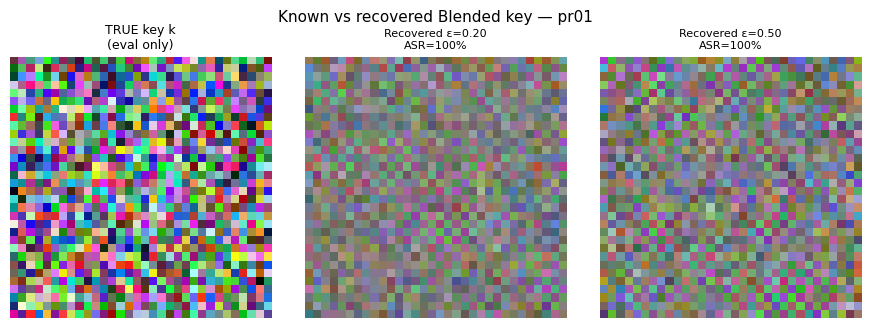

  [gate] select-slice CA tolerance used: 0.040 (report-half drop: 0.0294)

  RESULT (pr01): SUCCESS | CA 94.95→92.01% | ASR 99.99→0.15% | selected epoch 15  [heldout CA floor -> proxy ASR (tie_tol=0.005)]
  [ORACLE upper bound, uses real ASR — NOT a result] epoch 15: CA 92.01% / ASR 0.15%
  Reload verification PASSED ✓
  Audits (fresh recovery on select slice; fresh UAP on report half) ...
    {'poisoned_fresh_max_asr': 1.0, 'poisoned_fresh_accepted': 2, 'poisoned_fresh_seconds': 41.3, 'poisoned_uap_asr': 1.0, 'sanitized_fresh_max_asr': 1.0, 'sanitized_fresh_accepted': 2, 'sanitized_fresh_seconds': 40.3, 'sanitized_uap_asr': 0.9902}


In [10]:
# ════════════════════════════════════════════════════════════════════════
# Cell H1 — pr01  (SMOKE TEST — inspect held-out ASR / Pearson / audits before continuing)
# ════════════════════════════════════════════════════════════════════════
if 'pr01' in PR_TAGS:
    _res01, _ = run_baeraser_pipeline('pr01')
else:
    print('pr01 not in ACTIVE_TAGS — skipped.')



BAERASER-LITE: pr05 | op=blended α=0.1 | independent fresh init | protocol=heldout_test_split | fresh_select_k=1
  [coarse] recovery epsilon=0.20
    exact ASR=100.00% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=100.00% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.

  RECOVERY: epsilons tried=2 accepted=2 time=41s | init_mode=random fresh_init_verified=True | acceptance split=heldout
pr_tag  idx  epsilon  defence_asr  heldout_asr  pearson_vs_true_key  trigger_std
  pr05    0      0.2          1.0          1.0               0.0048       0.1650
  pr05    1      0.5          1.0          1.0              -0.0068       0.1127


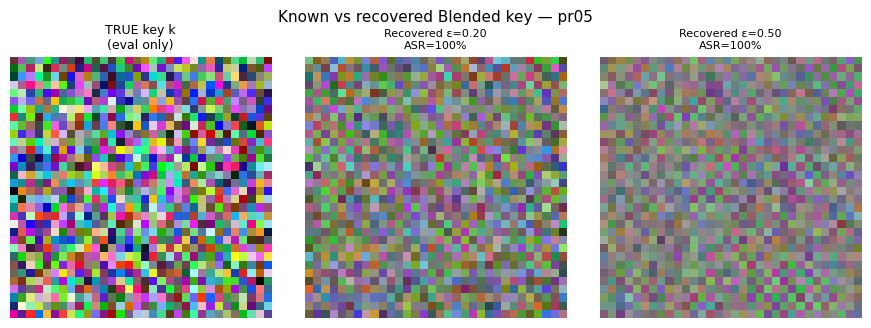

  [gate] select-slice CA tolerance used: 0.040 (report-half drop: 0.0364)

  RESULT (pr05): SUCCESS | CA 94.81→91.17% | ASR 100.00→1.33% | selected epoch 12  [heldout CA floor -> proxy ASR (tie_tol=0.005)]
  [ORACLE upper bound, uses real ASR — NOT a result] epoch 15: CA 91.11% / ASR 0.87%
  Reload verification PASSED ✓
  Audits (fresh recovery on select slice; fresh UAP on report half) ...
    {'poisoned_fresh_max_asr': 1.0, 'poisoned_fresh_accepted': 2, 'poisoned_fresh_seconds': 41.4, 'poisoned_uap_asr': 1.0, 'sanitized_fresh_max_asr': 1.0, 'sanitized_fresh_accepted': 2, 'sanitized_fresh_seconds': 40.8, 'sanitized_uap_asr': 1.0}

BAERASER-LITE: pr10 | op=blended α=0.1 | independent fresh init | protocol=heldout_test_split | fresh_select_k=1
  [coarse] recovery epsilon=0.20
    exact ASR=100.00% [ACCEPTED]
  [coarse] recovery epsilon=0.50
    exact ASR=100.00% [ACCEPTED]
    -> 2 accepted triggers, stopping recovery early.

  RECOVERY: epsilons tried=2 accepted=2 time=41s | init_mode=

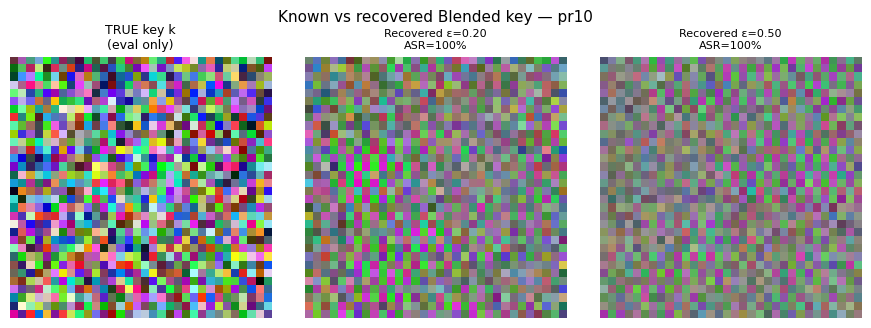

  [gate] select-slice CA tolerance used: 0.040 (report-half drop: 0.0171)

  RESULT (pr10): SUCCESS | CA 94.48→92.77% | ASR 100.00→16.73% | selected epoch 1  [heldout CA floor -> proxy ASR (tie_tol=0.005)]
  [ORACLE upper bound, uses real ASR — NOT a result] epoch 15: CA 92.87% / ASR 0.46%
  Reload verification PASSED ✓
  Audits (fresh recovery on select slice; fresh UAP on report half) ...
    {'poisoned_fresh_max_asr': 1.0, 'poisoned_fresh_accepted': 2, 'poisoned_fresh_seconds': 40.7, 'poisoned_uap_asr': 1.0, 'sanitized_fresh_max_asr': 1.0, 'sanitized_fresh_accepted': 2, 'sanitized_fresh_seconds': 40.8, 'sanitized_uap_asr': 1.0}

BaEraser-lite pipeline complete for active rates: ['pr01', 'pr05', 'pr10']


In [11]:
# ════════════════════════════════════════════════════════════════════════
# Cell H2 — remaining active rates (pr05, pr10). Each is an INDEPENDENT run (no warm start).
# With ACTIVE_TAGS = ['pr01'] this does nothing. Set ACTIVE_TAGS (cell A2) to all three and re-run from B2.
# ════════════════════════════════════════════════════════════════════════
for _tag in [t for t in PR_TAGS if t != 'pr01']:
    run_baeraser_pipeline(_tag)
print('\nBaEraser-lite pipeline complete for active rates:', PR_TAGS)


---
### Clean-model control (optional)

Runs the **identical** recovery + unlearning config on a CLEAN ResNet-18 and compares accepted-trigger count, held-out ASR and the fresh-trigger / fresh-UAP audits against the backdoored models. If the clean model accepts triggers just as often, the recovery is finding generic universal perturbations rather than the backdoor → reframe the method accordingly. Either way, disclose that the defender is given the blend family and α. Enable by setting `CLEAN_CKPT_PATH` in cell A2.

In [12]:
# ════════════════════════════════════════════════════════════════════════
# Cell H3 — Clean-model control (same config as the backdoored runs)
# ════════════════════════════════════════════════════════════════════════
clean_control = {}
if CLEAN_CKPT_PATH and os.path.isfile(CLEAN_CKPT_PATH):
    set_seed(SEED)
    _cm = _load_ckpt(CLEAN_CKPT_PATH)
    _cca, _casr = evaluate_model(_cm)
    print(f'CLEAN model: CA(report)={_cca*100:.2f}%  blend-trigger ASR(report)={_casr*100:.2f}%  (the trigger should NOT work here)')
    _pool, _cands, _meta = BL.recover_trigger_pool(_cm, defense_loader, TARGET_CLASS, operator, device=DEVICE,
                                                   seed=SEED, heldout_loader=select_loader)
    assert _meta['init_mode'] == 'random' and _meta['fresh_init_verified'] is True
    clean_control = {'model': 'clean', 'CA': round(_cca, 4), 'ASR_blend_trigger': round(_casr, 4),
                     'epsilons_tried': _meta['n_epsilons_tried'], 'accepted': _meta['n_accepted'],
                     'max_candidate_asr': round(max((c['candidate_asr'] for c in _cands), default=0.0), 4),
                     'recovery_seconds': round(_meta['wall_clock_seconds'])}
    if _pool:
        set_seed(SEED)
        _cu = copy.deepcopy(_cm)
        _ur = BL.baeraser_unlearning(_cu, defense_loader, _pool, operator, TARGET_CLASS,
                                     calculate_ca=calculate_ca, ca_loader=testloader,
                                     calculate_asr=calculate_asr, asr_loader=asr_loader, device=DEVICE,
                                     ca_before=_cca, asr_before=_casr, select_loader=select_loader,
                                     fresh_select_k=FRESH_SELECT_K, allow_leaky_selection=(select_loader is None), seed=SEED,
                                     ca_drop_tolerance=BL.CA_DROP_TOLERANCE - (CA_SELECT_MARGIN if select_loader is not None else 0.0))
        clean_control.update({'status': _ur['status'], 'CA_after': _ur['CA_after'], 'ASR_blend_after': _ur['ASR_after']})
        _cm_after = _cu
    else:
        _cm_after = None
    if RUN_FRESH_AUDIT and select_loader is not None:
        clean_control.update(audit_model(_cm, 'clean_before'))
        if _cm_after is not None:
            clean_control.update(audit_model(_cm_after, 'clean_after'))
    pd.DataFrame([clean_control]).to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_clean_control.csv', index=False)
    print('\nCLEAN-MODEL CONTROL:'); print(pd.DataFrame([clean_control]).T.to_string(header=False))
    for _t in PR_TAGS:
        _m = all_recovery_meta.get(_t)
        if _m: print(f'  vs backdoored {_t}: accepted {_m["n_accepted"]}/{_m["n_epsilons_tried"]} (clean: {clean_control["accepted"]}/{clean_control["epsilons_tried"]})')
    if clean_control['accepted'] > 0:
        print('  ⚠️  The clean model ALSO accepts recovered triggers → the recovery finds generic universal perturbations; '
              'reframe the method (not "key recovery") and report this control.')
    del _cm
else:
    print('Clean-model control SKIPPED (set CLEAN_CKPT_PATH in cell A2 to a clean ResNet-18 state_dict to enable).')


Clean-model control SKIPPED (set CLEAN_CKPT_PATH in cell A2 to a clean ResNet-18 state_dict to enable).


---
## Section I — Results & Plots

In [13]:
# ════════════════════════════════════════════════════════════════════════
# Cell I1 — Master Results Table
# ════════════════════════════════════════════════════════════════════════
master_rows = []
for _tag in PR_TAGS:
    _r, _d = all_results[_tag], all_diag_rows.get(_tag, [])
    _asr_after = _r.get('ASR_after')
    master_rows.append({
        'attack': ATTACK_NAME, 'poison_rate': PR_MAP[_tag], 'pr_tag': _tag,
        'operator': operator.name, 'alpha_blend': operator.alpha, 'trigger_dim': TRIGGER_DIM,
        'CA_before': _r.get('CA_before'), 'ASR_before': _r.get('ASR_before'),
        'CA_after': _r.get('CA_after'), 'ASR_after': _asr_after,
        'CA_drop': _r.get('CA_drop'), 'ASR_reduction_abs': _r.get('ASR_reduction_abs'),
        'ASR_reduction_rel': _r.get('ASR_reduction_rel'),
        'candidates_trained': len(all_candidates.get(_tag, [])),
        'candidates_accepted': len(all_trigger_pools.get(_tag, [])),
        'best_heldout_trigger_asr': max([x['heldout_asr'] for x in _d], default=None),
        'best_pearson_vs_true_key': max([x['pearson_vs_true_key'] for x in _d], default=None),
        'unlearning_best_epoch': _r.get('best_epoch'),
        'selection_rule': _r.get('selection_rule'), 'sel_proxy_ASR': _r.get('sel_proxy_ASR'),
        'sel_fresh_ASR': _r.get('sel_fresh_ASR'),
        'ORACLE_epoch(upper bound)': _r.get('oracle_epoch'), 'ORACLE_ASR(upper bound)': _r.get('oracle_ASR'),
        'ORACLE_CA(upper bound)': _r.get('oracle_CA'),
        'recovery_s': _r.get('recovery_seconds'), 'unlearning_s': _r.get('unlearning_seconds'),
        'total_cost_s': _r.get('total_cost_seconds'), 'fresh_init_verified': _r.get('fresh_init_verified'),
        'protocol': PROTOCOL, 'split_sha': SPLIT_SHA,
        'CA_drop_exceeds_tolerance': (_r.get('CA_drop') is not None and _r['CA_drop'] > BL.CA_DROP_TOLERANCE),
        'defence_effective(ASR_after<10%)': (None if _asr_after is None else bool(_asr_after < 0.10)),
        'status': _r.get('status', 'UNKNOWN')})
master_df = pd.DataFrame(master_rows)
master_df.to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_master_results.csv', index=False)
pd.DataFrame([r for t in PR_TAGS for r in all_diag_rows.get(t, [])]).to_csv(
    f'{BAERASER_CSV_DIR}/blended_baeraser_trigger_diagnostics.csv', index=False)

_show = ['pr_tag','CA_before','ASR_before','CA_after','ASR_after','CA_drop','candidates_accepted',
         'best_heldout_trigger_asr','best_pearson_vs_true_key','defence_effective(ASR_after<10%)','status']
print('BAERASER DEFENCE RESULTS — BLENDED'); print('=' * 110)
print(master_df[_show].to_string(index=False))
print('\nSELECTION TRANSPARENCY (headline = selected epoch; ORACLE = best real-ASR epoch, an upper bound, never a result)')
_ext = ['pr_tag','unlearning_best_epoch','CA_after','ASR_after','sel_proxy_ASR','sel_fresh_ASR',
        'ORACLE_epoch(upper bound)','ORACLE_ASR(upper bound)','ORACLE_CA(upper bound)','total_cost_s']
print(master_df[_ext].to_string(index=False))

if all_audits:
    audit_df = pd.DataFrame(list(all_audits.values()))
    audit_df.to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_audits.csv', index=False)
    print('\nAUDITS — fresh recovery (select slice) and fresh universal perturbation (report half), poisoned vs sanitized')
    print(audit_df.T.to_string(header=False))


BAERASER DEFENCE RESULTS — BLENDED
pr_tag  CA_before  ASR_before  CA_after  ASR_after  CA_drop  candidates_accepted  best_heldout_trigger_asr  best_pearson_vs_true_key  defence_effective(ASR_after<10%)  status
  pr01     0.9495      0.9999  0.920133   0.001481   0.0294                    2                       1.0                   -0.0098                              True SUCCESS
  pr05     0.9481      1.0000  0.911733   0.013333   0.0364                    2                       1.0                    0.0048                              True SUCCESS
  pr10     0.9448      1.0000  0.927733   0.167259   0.0171                    2                       1.0                    0.0232                             False SUCCESS

SELECTION TRANSPARENCY (headline = selected epoch; ORACLE = best real-ASR epoch, an upper bound, never a result)
pr_tag  unlearning_best_epoch  CA_after  ASR_after  sel_proxy_ASR sel_fresh_ASR  ORACLE_epoch(upper bound)  ORACLE_ASR(upper bound)  ORACLE_CA(upper bo

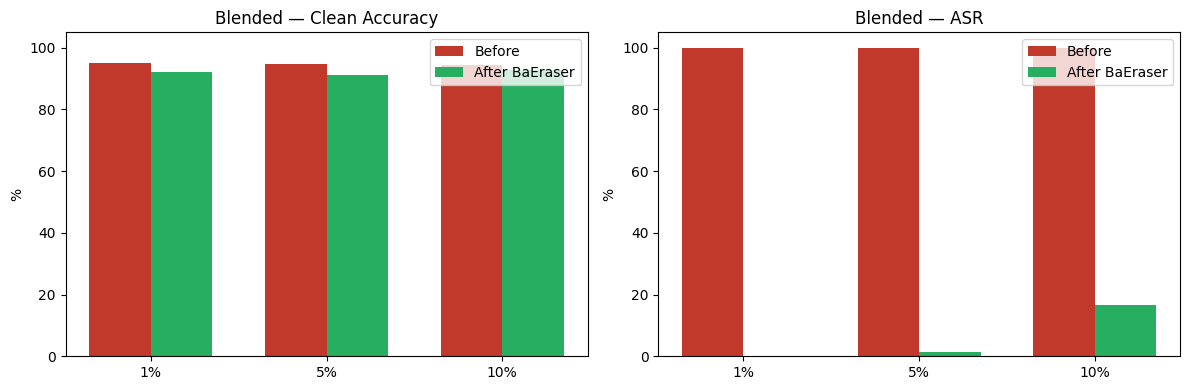

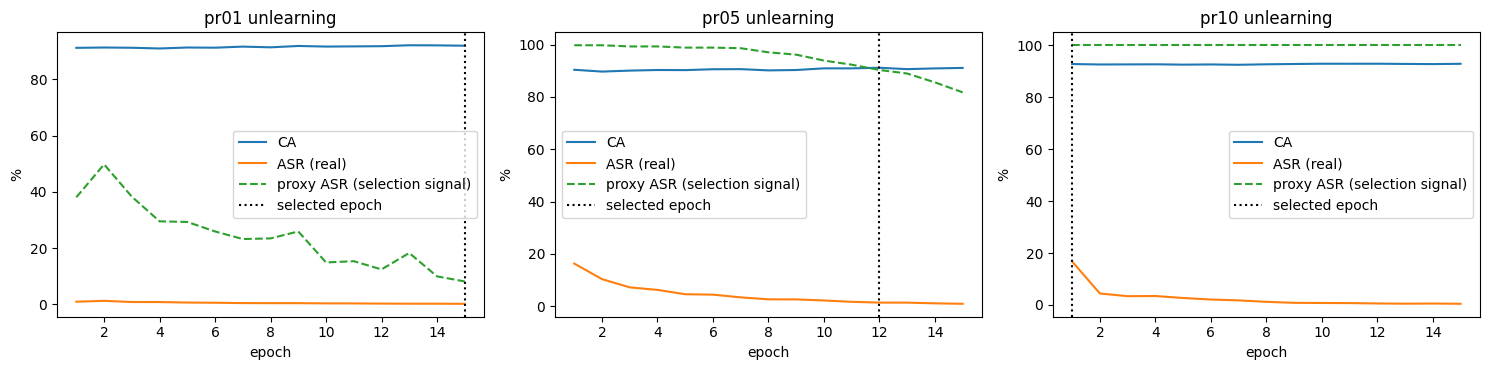

In [14]:
# ════════════════════════════════════════════════════════════════════════
# Cell I2 — Before/After CA & ASR + Unlearning Curves
# ════════════════════════════════════════════════════════════════════════
_valid = [t for t in PR_TAGS if all_results[t].get('CA_after') is not None]
if _valid:
    fig, ax = plt.subplots(1, 2, figsize=(12, 4)); x = np.arange(len(_valid)); w = 0.35
    for a, (b, af, title) in zip(ax, [('CA_before','CA_after','Clean Accuracy'), ('ASR_before','ASR_after','ASR')]):
        a.bar(x - w/2, [all_results[t][b]*100 for t in _valid], w, label='Before', color='#c0392b')
        a.bar(x + w/2, [all_results[t][af]*100 for t in _valid], w, label='After BaEraser', color='#27ae60')
        a.set_xticks(x); a.set_xticklabels([f'{PR_MAP[t]*100:.0f}%' for t in _valid])
        a.set_ylabel('%'); a.set_title(f'Blended — {title}'); a.legend(); a.set_ylim(0, 105)
    plt.tight_layout(); plt.savefig(f'{BAERASER_FIG_DIR}/blended_baeraser_before_after.png', dpi=150); plt.show()

    fig, ax = plt.subplots(1, len(_valid), figsize=(5*len(_valid), 3.8), squeeze=False)
    for a, t in zip(ax[0], _valid):
        L = pd.DataFrame(all_unlearn_logs[t])
        a.plot(L['epoch'], L['clean_acc']*100, label='CA'); a.plot(L['epoch'], L['asr']*100, label='ASR (real)')
        if 'sel_proxy_ASR' in L and L['sel_proxy_ASR'].notna().any():
            a.plot(L['epoch'], L['sel_proxy_ASR'].astype(float)*100, '--', label='proxy ASR (selection signal)')
        if all_results[t].get('best_epoch'): a.axvline(all_results[t]['best_epoch'], color='k', ls=':', label='selected epoch')
        a.set_title(f'{t} unlearning'); a.set_xlabel('epoch'); a.set_ylabel('%'); a.legend()
    plt.tight_layout(); plt.savefig(f'{BAERASER_FIG_DIR}/blended_baeraser_curves.png', dpi=150); plt.show()
else:
    print('No defended models to plot (all runs failed).')

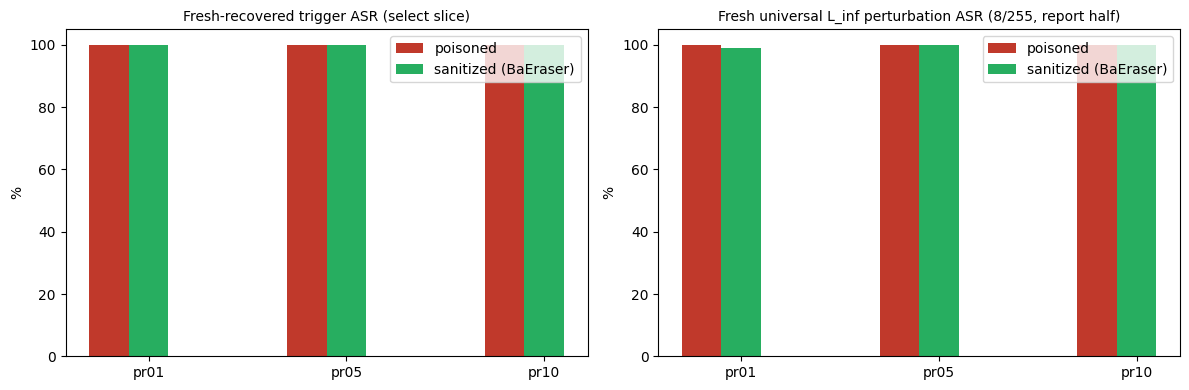

Reading guide: sanitized fresh-trigger ASR ~ poisoned => new triggers still work (model not robust to the family);
UAP ASR dropping together with the backdoor ASR => part of the gain is generic adversarial robustness.


In [15]:
# ════════════════════════════════════════════════════════════════════════
# Cell I3 — Audit plot: does the sanitized model stay vulnerable to FRESH triggers / UAPs?   [new in v3]
# ════════════════════════════════════════════════════════════════════════
if all_audits:
    _tags = list(all_audits.keys()); x = np.arange(len(_tags)); w = 0.2
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, (key, title) in zip(ax, [('fresh_max_asr', 'Fresh-recovered trigger ASR (select slice)'),
                                    ('uap_asr', 'Fresh universal L_inf perturbation ASR (8/255, report half)')]):
        a.bar(x - w, [all_audits[t][f'poisoned_{key}']*100 for t in _tags], w, label='poisoned', color='#c0392b')
        a.bar(x,     [all_audits[t][f'sanitized_{key}']*100 for t in _tags], w, label='sanitized (BaEraser)', color='#27ae60')
        if clean_control and f'clean_before_{key}' in clean_control:
            a.axhline(clean_control[f'clean_before_{key}']*100, color='gray', ls='--', label='clean model (control)')
        a.set_xticks(x); a.set_xticklabels(_tags); a.set_ylabel('%'); a.set_ylim(0, 105); a.set_title(title, fontsize=10); a.legend()
    plt.tight_layout(); plt.savefig(f'{BAERASER_FIG_DIR}/blended_baeraser_audits.png', dpi=150); plt.show()
    print('Reading guide: sanitized fresh-trigger ASR ~ poisoned => new triggers still work (model not robust to the family);'
          '\nUAP ASR dropping together with the backdoor ASR => part of the gain is generic adversarial robustness.')
else:
    print('No audits available (RUN_FRESH_AUDIT=False, legacy protocol, or no successful run).')


In [16]:
# ════════════════════════════════════════════════════════════════════════
# Cell I4 — Per-class accuracy + clean-image airplane-prediction rate   [new in v3.1]
# ════════════════════════════════════════════════════════════════════════
# Does a ~0% ASR mean the backdoor is gone, or that the model stopped predicting the target class?
# Compare ASR with the model's NATURAL rate of predicting airplane on clean non-airplane report images.
CIFAR_CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

def per_class_report(model, loader, target):
    model.eval(); P, Y = [], []
    with torch.no_grad():
        for x, y in loader:
            P.append(model(x.to(DEVICE)).argmax(1).cpu()); Y.append(y)
    p, y = torch.cat(P).numpy(), torch.cat(Y).numpy()
    acc = [float((p[y == c] == c).mean()) for c in range(10)]
    nt = y != target
    return acc, float((p[nt] == target).mean())

_rows = []
for _t in PR_TAGS:
    _models = {'baseline': load_backdoored_model(_t)}
    if all_best_ckpts.get(_t) and os.path.isfile(all_best_ckpts[_t]):
        _models['baeraser'] = _load_ckpt(all_best_ckpts[_t])
    for _name, _m in _models.items():
        _acc, _ct = per_class_report(_m, testloader, TARGET_CLASS)
        _asr = evaluate_model(_m)[1]
        _rows.append({'pr_tag': _t, 'stage': _name, **{f'acc_{CIFAR_CLASS_NAMES[c]}': round(_acc[c]*100, 2) for c in range(10)},
                      'mean_class_acc': round(float(np.mean(_acc))*100, 2),
                      'clean_non_target→airplane (%)': round(_ct*100, 3), 'ASR (%)': round(_asr*100, 3)})
        del _m
    torch.cuda.empty_cache()
df_perclass = pd.DataFrame(_rows)
print('PER-CLASS ACCURACY (report half, %) + natural airplane-prediction rate'); print(df_perclass.to_string(index=False))
df_perclass.to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_per_class_accuracy.csv', index=False)
for _t in PR_TAGS:
    _d = df_perclass[df_perclass.pr_tag == _t].set_index('stage')
    if 'baeraser' not in _d.index: continue
    _floor = _d.loc['baseline', 'clean_non_target→airplane (%)']
    _flag = '  ← ASR is BELOW the clean model\'s natural airplane rate: the sanitized model under-predicts airplane' \
            if (_d.loc['baeraser', 'ASR (%)'] < _floor and _d.loc['baeraser', 'clean_non_target→airplane (%)'] < _floor) else ''
    print(f"  {_t}: airplane recall {_d.loc['baseline','acc_airplane']:.1f}→{_d.loc['baeraser','acc_airplane']:.1f}% | "
          f"clean→airplane {_floor:.2f}→{_d.loc['baeraser','clean_non_target→airplane (%)']:.2f}% | ASR {_d.loc['baeraser','ASR (%)']:.2f}%{_flag}")


PER-CLASS ACCURACY (report half, %) + natural airplane-prediction rate
pr_tag    stage  acc_airplane  acc_automobile  acc_bird  acc_cat  acc_deer  acc_dog  acc_frog  acc_horse  acc_ship  acc_truck  mean_class_acc  clean_non_target→airplane (%)  ASR (%)
  pr01 baseline         96.80           98.53     93.87    89.20     95.60    90.00     97.33      96.13     96.53      95.47           94.95                          0.652   99.985
  pr01 baeraser         91.87           96.67     88.00    86.93     90.93    86.67     94.00      96.40     94.40      94.27           92.01                          0.593    0.148
  pr05 baseline         95.87           99.07     93.07    87.87     96.40    90.93     96.93      95.47     96.40      96.13           94.81                          0.607  100.000
  pr05 baeraser         95.33           94.93     86.93    84.00     90.13    84.93     93.33      95.73     92.27      94.13           91.17                          1.659    1.333
  pr10 baseline    

---
## Section J — STRIP Diagnostic (Before / After)

Behavioural diagnostic only. Parameters mirror attack-notebook Cell 20 (500 samples, 100 superimpositions, STRIP overlay α=0.5) so *before* numbers are comparable with `blended_main_strip_results.csv`.


=== STRIP: pr01 ===
Running STRIP on 250 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 250/250 [00:18<00:00, 13.36it/s]


Running STRIP on 250 clean samples...


100%|██████████| 250/250 [00:18<00:00, 13.45it/s]



STRIP Results:
  Clean entropy — mean: 0.4306, std: 0.1580
  Threshold (FRR=1%): 0.0630
  Min clean entropy:     0.0408
  Max triggered entropy: 0.9170
  TPR (detection rate):  10.00%
  FPR (false alarms):    1.20%
Saved: /content/drive/MyDrive/ps-capstone2/baeraser_blended_v3/strip/strip_before_pr01.png


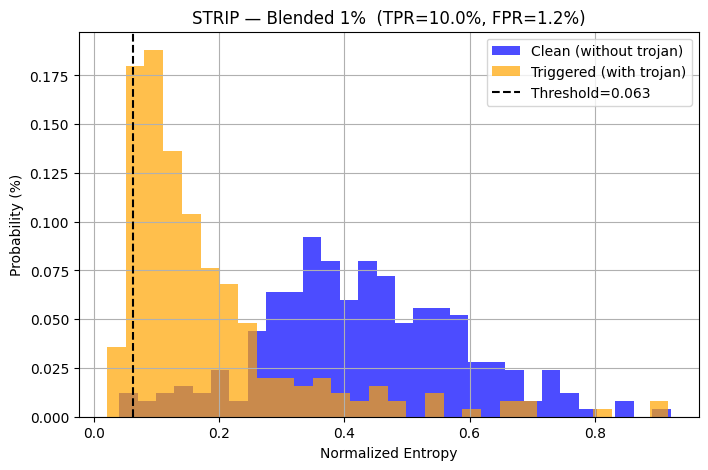

Running STRIP on 250 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 250/250 [00:19<00:00, 13.05it/s]


Running STRIP on 250 clean samples...


100%|██████████| 250/250 [00:18<00:00, 13.39it/s]



STRIP Results:
  Clean entropy — mean: 0.4279, std: 0.1505
  Threshold (FRR=1%): 0.0778
  Min clean entropy:     0.0035
  Max triggered entropy: 0.8756
  TPR (detection rate):  0.40%
  FPR (false alarms):    1.60%
Saved: /content/drive/MyDrive/ps-capstone2/baeraser_blended_v3/strip/strip_after_pr01.png


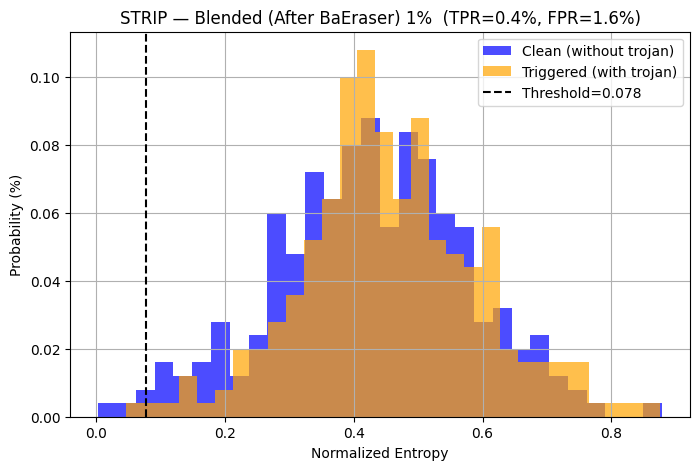

  BEFORE: TPR=10.00% FPR=1.20% mu=0.4306
  AFTER : TPR=0.40% FPR=1.60% mu=0.4279

=== STRIP: pr05 ===
Running STRIP on 250 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 250/250 [00:19<00:00, 13.03it/s]


Running STRIP on 250 clean samples...


100%|██████████| 250/250 [00:19<00:00, 13.14it/s]



STRIP Results:
  Clean entropy — mean: 0.4671, std: 0.1639
  Threshold (FRR=1%): 0.0857
  Min clean entropy:     0.0397
  Max triggered entropy: 0.7633
  TPR (detection rate):  24.40%
  FPR (false alarms):    1.20%
Saved: /content/drive/MyDrive/ps-capstone2/baeraser_blended_v3/strip/strip_before_pr05.png


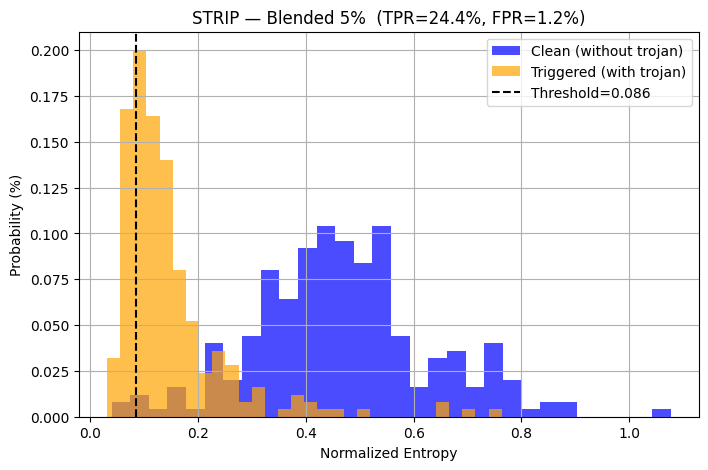

Running STRIP on 250 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 250/250 [00:18<00:00, 13.45it/s]


Running STRIP on 250 clean samples...


100%|██████████| 250/250 [00:18<00:00, 13.29it/s]



STRIP Results:
  Clean entropy — mean: 0.4322, std: 0.1615
  Threshold (FRR=1%): 0.0565
  Min clean entropy:     0.0310
  Max triggered entropy: 1.0158
  TPR (detection rate):  0.00%
  FPR (false alarms):    0.80%
Saved: /content/drive/MyDrive/ps-capstone2/baeraser_blended_v3/strip/strip_after_pr05.png


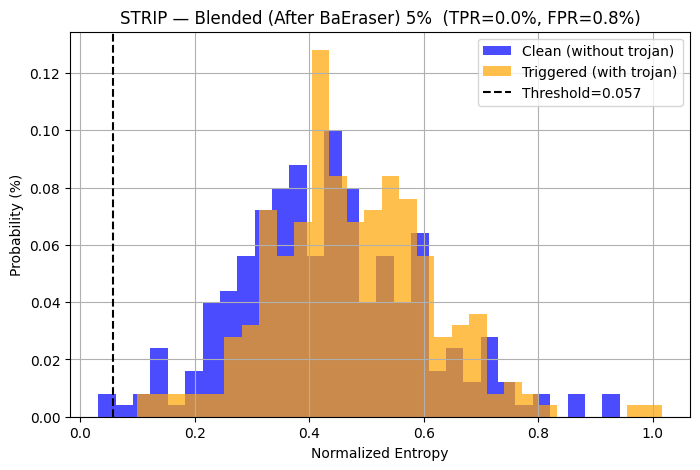

  BEFORE: TPR=24.40% FPR=1.20% mu=0.4671
  AFTER : TPR=0.00% FPR=0.80% mu=0.4322

=== STRIP: pr10 ===
Running STRIP on 250 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 250/250 [00:18<00:00, 13.50it/s]


Running STRIP on 250 clean samples...


100%|██████████| 250/250 [00:18<00:00, 13.52it/s]



STRIP Results:
  Clean entropy — mean: 0.4756, std: 0.1655
  Threshold (FRR=1%): 0.0906
  Min clean entropy:     0.0178
  Max triggered entropy: 1.5092
  TPR (detection rate):  0.00%
  FPR (false alarms):    2.00%
Saved: /content/drive/MyDrive/ps-capstone2/baeraser_blended_v3/strip/strip_before_pr10.png


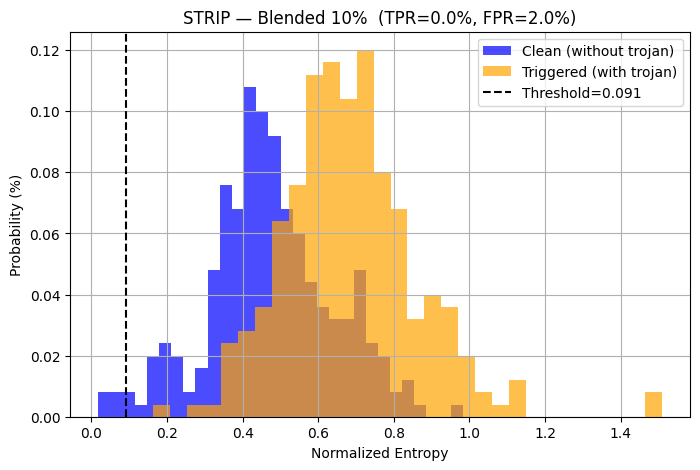

Running STRIP on 250 triggered samples (from shared asr_test_idx, batched inner loop)...


100%|██████████| 250/250 [00:19<00:00, 12.92it/s]


Running STRIP on 250 clean samples...


100%|██████████| 250/250 [00:18<00:00, 13.53it/s]



STRIP Results:
  Clean entropy — mean: 0.4051, std: 0.1421
  Threshold (FRR=1%): 0.0745
  Min clean entropy:     0.0246
  Max triggered entropy: 0.9274
  TPR (detection rate):  0.00%
  FPR (false alarms):    0.80%
Saved: /content/drive/MyDrive/ps-capstone2/baeraser_blended_v3/strip/strip_after_pr10.png


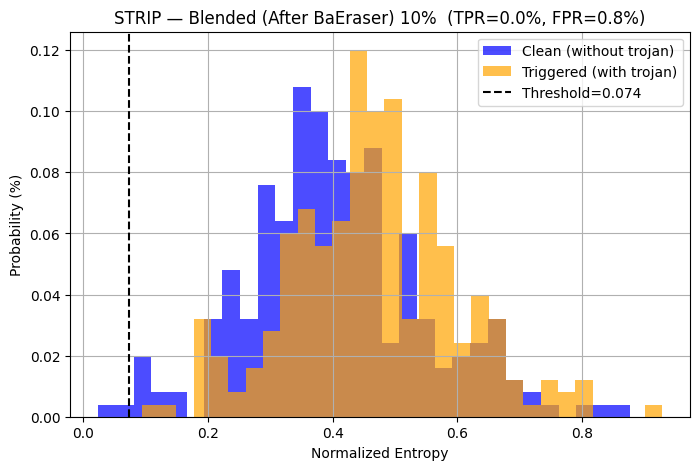

  BEFORE: TPR=0.00% FPR=2.00% mu=0.4756
  AFTER : TPR=0.00% FPR=0.80% mu=0.4051


In [17]:
# ════════════════════════════════════════════════════════════════════════
# Cell J1 — STRIP Before / After
# ════════════════════════════════════════════════════════════════════════
STRIP_N_SAMPLES, STRIP_N_SUPERIMPOSE, STRIP_FRR = 500, 100, 0.01
STRIP_ALPHA, STRIP_BATCH_SIZE = 0.5, 100          # STRIP overlay weight (NOT ALPHA_TEST)

def _blended_trigger_fn(img):
    return add_blended_trigger_global(img, blend_pattern, alpha=ALPHA_TEST)

def _strip(model):
    return run_strip(model=model, test_dataset_raw=testset_raw, clean_dataset_raw=testset_raw,
                     device=DEVICE, transform=transform_test, target_class=TARGET_CLASS,
                     trigger_fn=_blended_trigger_fn, asr_test_idx=asr_test_idx,
                     n_samples=STRIP_N_SAMPLES, n_superimpose=STRIP_N_SUPERIMPOSE,
                     frr=STRIP_FRR, alpha=STRIP_ALPHA, seed=SEED, batch_size=STRIP_BATCH_SIZE)

strip_rows = []
for _tag in PR_TAGS:
    print(f'\n=== STRIP: {_tag} ===')
    if all_results[_tag].get('status') != 'SUCCESS':
        print(f'  status={all_results[_tag].get("status")} → STRIP before/after comparison not valid.')
        strip_rows.append({'pr_tag': _tag, 'poison_rate': PR_MAP[_tag], 'status': all_results[_tag].get('status')})
        continue
    _mb = load_backdoored_model(_tag); _sb = _strip(_mb); del _mb
    np.save(f'{STRIP_DIR}/strip_before_{_tag}.npy', _sb['entropies'])
    plot_strip_results(_sb, 'Blended', PR_MAP[_tag], save_path=f'{STRIP_DIR}/strip_before_{_tag}.png')

    _ma = get_resnet18().to(DEVICE); _ma.load_state_dict(torch.load(all_best_ckpts[_tag], map_location=DEVICE)); _ma.eval()
    _sa = _strip(_ma); del _ma
    np.save(f'{STRIP_DIR}/strip_after_{_tag}.npy', _sa['entropies'])
    plot_strip_results(_sa, 'Blended (After BaEraser)', PR_MAP[_tag], save_path=f'{STRIP_DIR}/strip_after_{_tag}.png')
    torch.cuda.empty_cache()

    strip_rows.append({'pr_tag': _tag, 'poison_rate': PR_MAP[_tag], 'status': 'OK',
                       'TPR_before': _sb['TPR'], 'FPR_before': _sb['FPR'], 'mu_before': _sb['mu'],
                       'TPR_after': _sa['TPR'], 'FPR_after': _sa['FPR'], 'mu_after': _sa['mu']})
    print(f'  BEFORE: TPR={_sb["TPR"]:.2f}% FPR={_sb["FPR"]:.2f}% mu={_sb["mu"]:.4f}')
    print(f'  AFTER : TPR={_sa["TPR"]:.2f}% FPR={_sa["FPR"]:.2f}% mu={_sa["mu"]:.4f}')

pd.DataFrame(strip_rows).to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_strip.csv', index=False)

---
## Section K — Grad-CAM Attention Correlation (Before / After)

Bounding-box TAR is meaningless for a full-image blend, so — as in the attack notebook (Cell 21) — we report the **Pearson r between the Grad-CAM of a clean image and of its triggered twin**. Lower r = attention shifts more when the trigger is present = stronger trigger reliance. After a successful defence r should **rise** toward the clean-model level.

pr01: r 0.7896 → 0.8723 | trig→target 100% → 0%


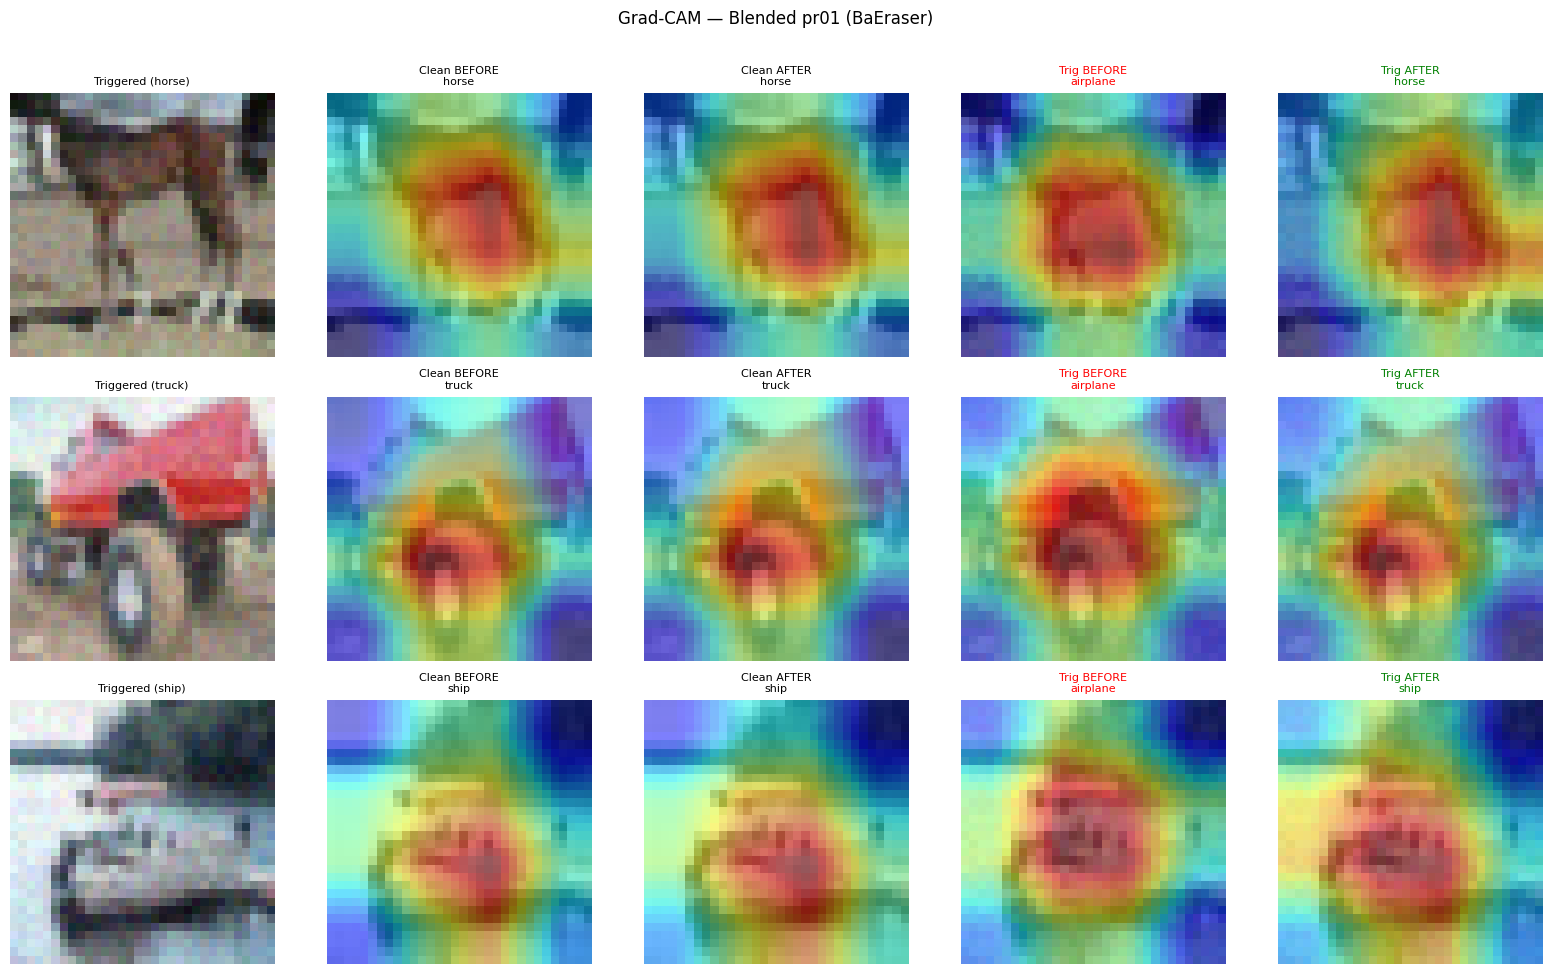

pr05: r 0.7526 → 0.8797 | trig→target 100% → 0%


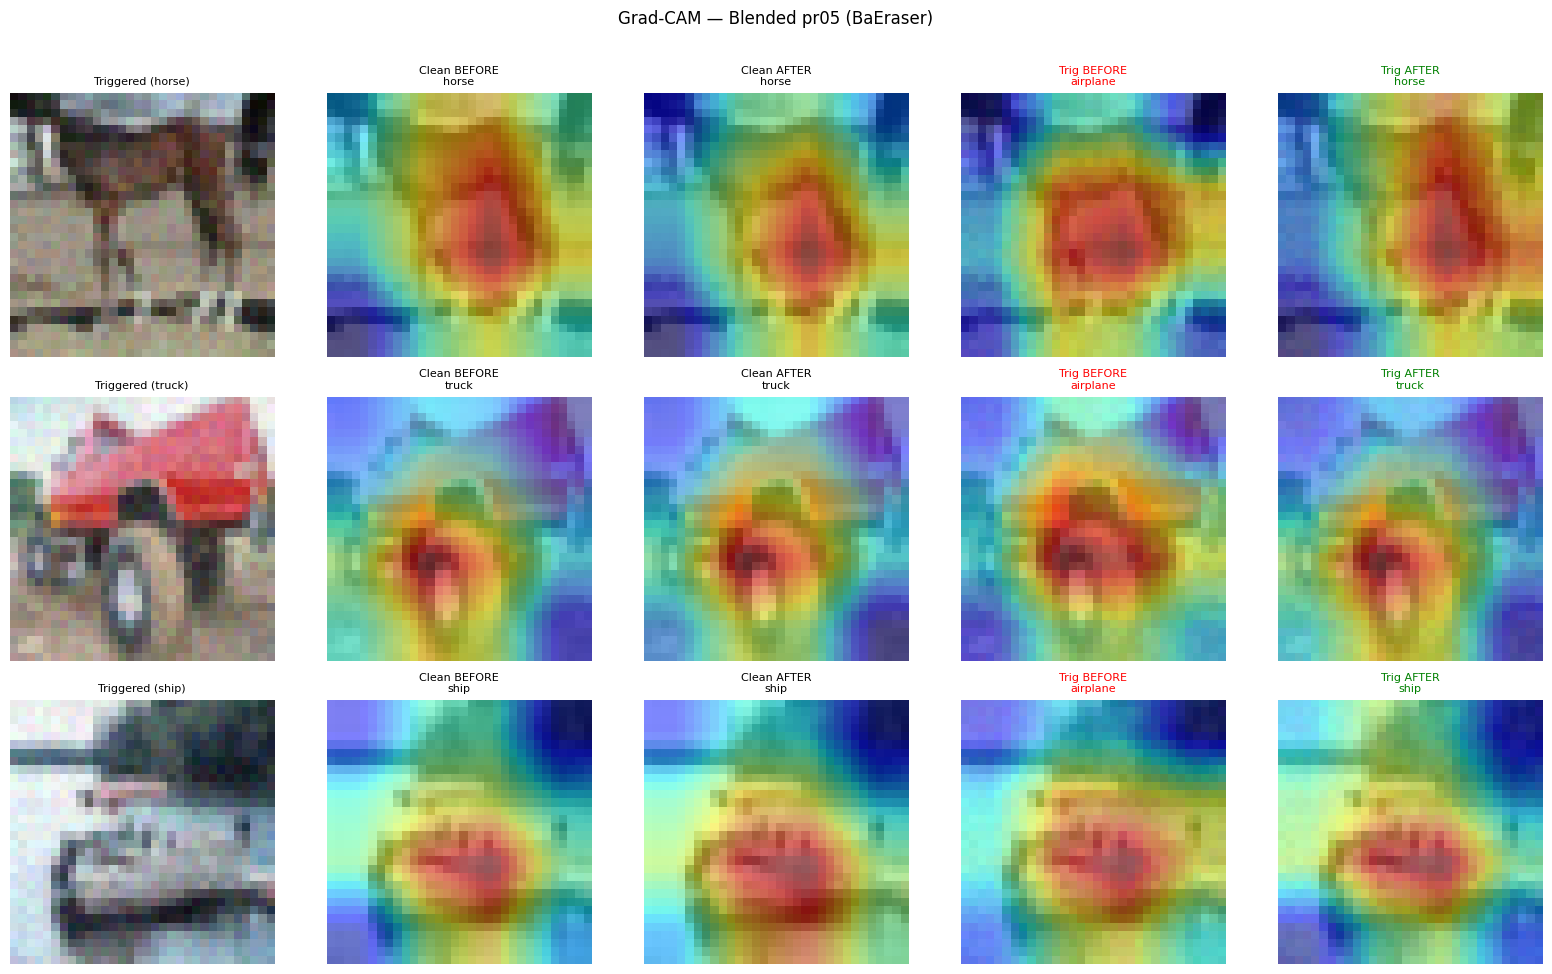

pr10: r 0.5600 → 0.6866 | trig→target 100% → 24%


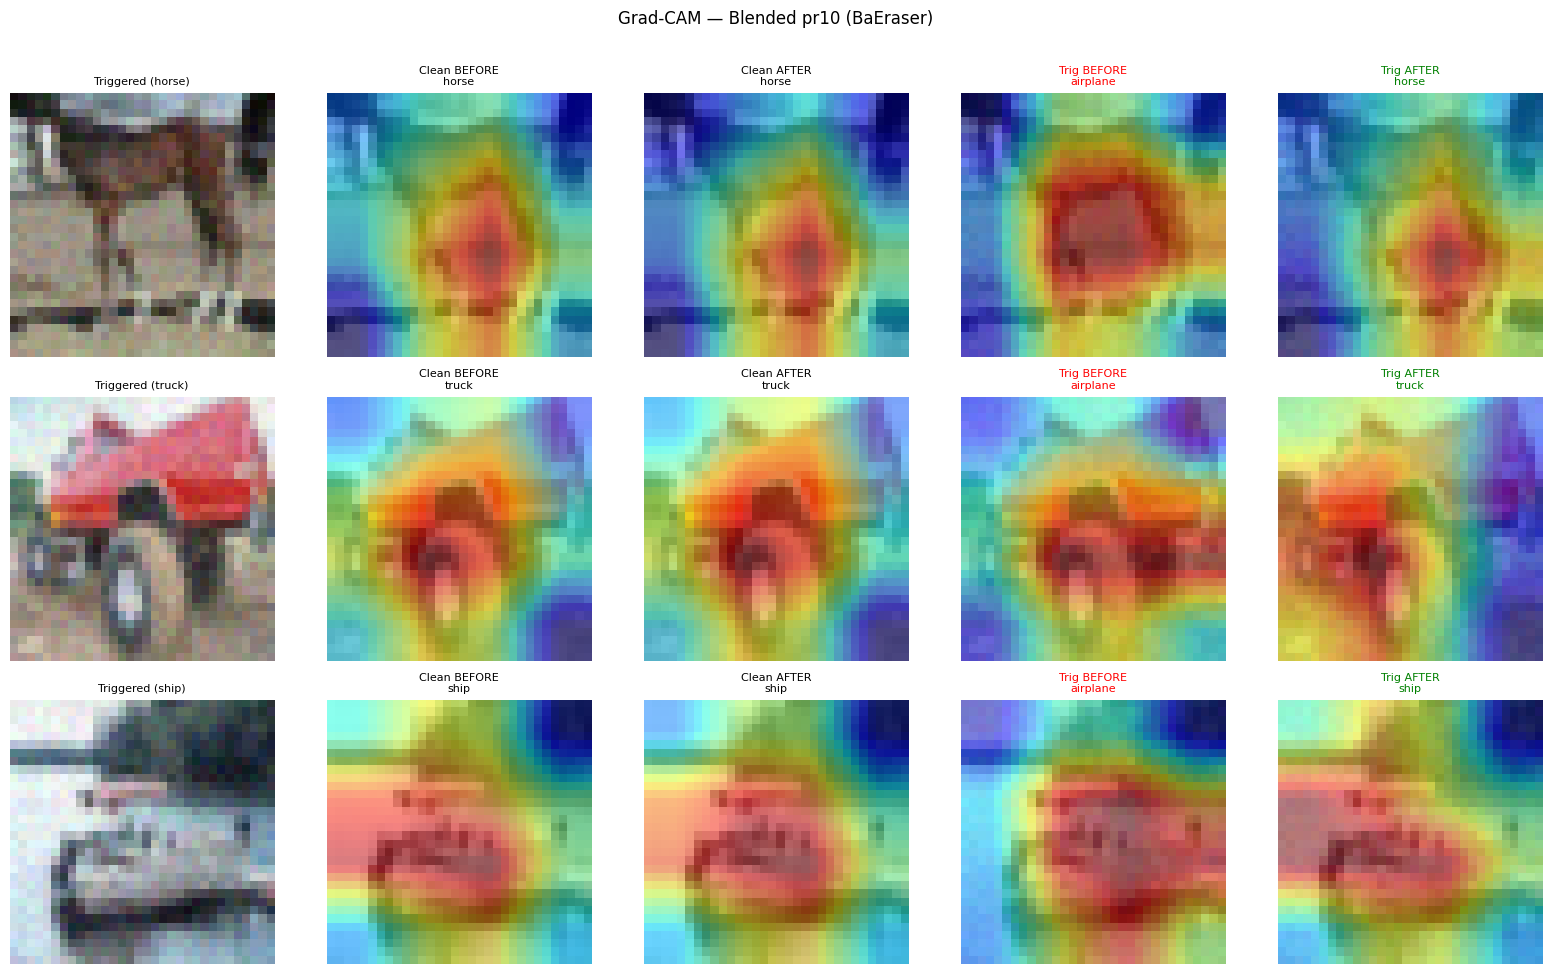


pr_tag  poison_rate  n  pearson_before_mean  pearson_before_std  pearson_after_mean  pearson_after_std  triggered→target_before  triggered→target_after
  pr01         0.01 50               0.7896              0.1644              0.8723             0.2075                      1.0                    0.00
  pr05         0.05 50               0.7526              0.1665              0.8797             0.1245                      1.0                    0.00
  pr10         0.10 50               0.5600              0.2879              0.6866             0.2961                      1.0                    0.24


In [18]:
# ════════════════════════════════════════════════════════════════════════
# Cell K1 — Grad-CAM attention correlation, before vs after BaEraser (+ visual panel)
# ════════════════════════════════════════════════════════════════════════
from scipy.stats import pearsonr
CIFAR10_CLASSES = ['airplane','automobile','bird','cat','deer','dog','frog','horse','ship','truck']
GRADCAM_LAYER, N_GRADCAM_SAMPLES, N_VIS = 'layer4', 50, 3

class GradCAM:
    def __init__(self, model, layer_name=GRADCAM_LAYER):
        self.model = model; self.act = self.grad = None
        layer = dict(model.named_modules())[layer_name]
        layer.register_forward_hook(lambda m, i, o: setattr(self, 'act', o.detach()))
        layer.register_full_backward_hook(lambda m, gi, go: setattr(self, 'grad', go[0].detach()))
    def __call__(self, x):
        self.model.zero_grad(); out = self.model(x); pred = out.argmax(1)
        out[0, pred].backward()
        cam = F.relu((self.grad.mean((2, 3), keepdim=True) * self.act).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=(32, 32), mode='bilinear', align_corners=False).squeeze().cpu().numpy()
        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8), int(pred.item())

def _to_t(img_u8):
    t = torch.from_numpy(img_u8.astype(np.float32) / 255.0).permute(2, 0, 1)
    t = (t - torch.tensor(CIFAR_MEAN).view(3,1,1)) / torch.tensor(CIFAR_STD).view(3,1,1)
    return t.unsqueeze(0).to(DEVICE)

_gc_idx = np.random.RandomState(SEED).choice(asr_test_idx, size=N_GRADCAM_SAMPLES, replace=False)

def _corr_for(model):
    cam = GradCAM(model); rs, preds = [], []
    for i in _gc_idx:
        c = testset_raw.data[i]; t = add_blended_trigger_global(c, blend_pattern, alpha=ALPHA_TEST)
        cc, _ = cam(_to_t(c)); tc, tp = cam(_to_t(t))
        rs.append(pearsonr(cc.flatten(), tc.flatten())[0]); preds.append(tp)
    return np.array(rs), np.array(preds)

gradcam_rows = []
for _tag in PR_TAGS:
    if all_results[_tag].get('status') != 'SUCCESS':
        print(f'{_tag}: status={all_results[_tag].get("status")} → Grad-CAM comparison not valid.'); continue
    _mb = load_backdoored_model(_tag)
    _ma = get_resnet18().to(DEVICE); _ma.load_state_dict(torch.load(all_best_ckpts[_tag], map_location=DEVICE)); _ma.eval()
    rb, pb = _corr_for(_mb); ra, pa = _corr_for(_ma)
    gradcam_rows.append({'pr_tag': _tag, 'poison_rate': PR_MAP[_tag], 'n': N_GRADCAM_SAMPLES,
                         'pearson_before_mean': rb.mean(), 'pearson_before_std': rb.std(),
                         'pearson_after_mean': ra.mean(), 'pearson_after_std': ra.std(),
                         'triggered→target_before': float((pb == TARGET_CLASS).mean()),
                         'triggered→target_after':  float((pa == TARGET_CLASS).mean())})
    print(f'{_tag}: r {rb.mean():.4f} → {ra.mean():.4f} | trig→target {(pb==TARGET_CLASS).mean()*100:.0f}% → {(pa==TARGET_CLASS).mean()*100:.0f}%')

    camb, cama = GradCAM(_mb), GradCAM(_ma)
    fig, axg = plt.subplots(N_VIS, 5, figsize=(16, 3.2 * N_VIS))
    for j, i in enumerate(_gc_idx[:N_VIS]):
        c = testset_raw.data[i]; t = add_blended_trigger_global(c, blend_pattern, alpha=ALPHA_TEST)
        (ccb, pcb), (ccA, pcA) = camb(_to_t(c)), cama(_to_t(c))
        (tcb, ptb), (tcA, ptA) = camb(_to_t(t)), cama(_to_t(t))
        for a, (im, cm, ttl, col) in zip(axg[j], [
            (t, None, f'Triggered ({CIFAR10_CLASSES[testset_raw.targets[i]]})', 'black'),
            (c, ccb, f'Clean BEFORE\n{CIFAR10_CLASSES[pcb]}', 'black'),
            (c, ccA, f'Clean AFTER\n{CIFAR10_CLASSES[pcA]}', 'black'),
            (t, tcb, f'Trig BEFORE\n{CIFAR10_CLASSES[ptb]}', 'red' if ptb == TARGET_CLASS else 'black'),
            (t, tcA, f'Trig AFTER\n{CIFAR10_CLASSES[ptA]}', 'red' if ptA == TARGET_CLASS else 'green')]):
            a.imshow(im)
            if cm is not None: a.imshow(cm, cmap='jet', alpha=0.5)
            a.set_title(ttl, fontsize=8, color=col); a.axis('off')
    plt.suptitle(f'Grad-CAM — Blended {_tag} (BaEraser)', y=1.01)
    plt.tight_layout(); plt.savefig(f'{GRADCAM_DIR}/gradcam_blended_baeraser_{_tag}.png', dpi=150, bbox_inches='tight'); plt.show()
    del _mb, _ma; torch.cuda.empty_cache()

if gradcam_rows:
    _g = pd.DataFrame(gradcam_rows); _g.to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_gradcam_corr.csv', index=False)
    print(); print(_g.round(4).to_string(index=False))

---
## Section L — Known vs Recovered Key (post-hoc)

Quantifies whether the recovered `k` resembles the true key. The true pattern is i.i.d. uniform noise, so a *real* recovery would show clearly positive Pearson r; r ≈ 0 with high held-out ASR is the signature of a UAP-style shortcut, not key recovery.

In [19]:
# ════════════════════════════════════════════════════════════════════════
# Cell L1 — Recovered vs true key: similarity table
# ════════════════════════════════════════════════════════════════════════
_rows = [r for t in PR_TAGS for r in all_diag_rows.get(t, [])]
if _rows:
    _df = pd.DataFrame(_rows)
    print(_df.groupby('pr_tag')[['defence_asr','heldout_asr','pearson_vs_true_key']]
              .agg(['mean','max']).round(4).to_string())
    print('\nInterpretation guide:')
    print('  high held-out ASR + Pearson r ≈ 0   → generator found a UAP-like perturbation, NOT the real key')
    print('  high held-out ASR + Pearson r  >> 0 → genuine (partial) key recovery')
    print('  low  held-out ASR                   → candidate overfit the 2,500 defence images')
else:
    print('No accepted triggers at any rate → Blended recovery FAILED (log this as a result).')

       defence_asr      heldout_asr      pearson_vs_true_key        
              mean  max        mean  max                mean     max
pr_tag                                                              
pr01           1.0  1.0         1.0  1.0             -0.0113 -0.0098
pr05           1.0  1.0         1.0  1.0             -0.0010  0.0048
pr10           1.0  1.0         1.0  1.0              0.0010  0.0232

Interpretation guide:
  high held-out ASR + Pearson r ≈ 0   → generator found a UAP-like perturbation, NOT the real key
  high held-out ASR + Pearson r  >> 0 → genuine (partial) key recovery
  low  held-out ASR                   → candidate overfit the 2,500 defence images


---
## Section M — Metadata, Cost & Conclusion

In [20]:
# ════════════════════════════════════════════════════════════════════════
# Cell M1 — Metadata + compute-cost table
# ════════════════════════════════════════════════════════════════════════
metadata = {
    'defense_method': 'BaEraser-lite (baeraser_lite.py; after Liu et al., IEEE INFOCOM 2022)',
    'attack': ATTACK_NAME, 'target_class': TARGET_CLASS, 'seed': SEED,
    'alpha_train': ALPHA_TRAIN, 'alpha_test': ALPHA_TEST, 'warm_start': WARM_START,
    'operator': {**operator.metadata(), 'class': type(operator).__name__,
                 'note': 'colour-space-corrected subclass of baeraser_lite.BlendedTriggerOperator'},
    'recovery_config': BL.ATTACK_RECOVERY_CONFIG['blended'], 'acceptance_threshold': BAERASER_RECOVERY_ASR_THRESHOLD,
    'unlearning': {'alpha': BL.BAERASER_ALPHA, 'beta': BL.BAERASER_BETA, 'lr': BL.BAERASER_UNLEARN_LR,
                   'momentum': BL.BAERASER_UNLEARN_MOMENTUM, 'max_epochs': BL.BAERASER_MAX_UNLEARNING_EPOCHS,
                   'omega_update_freq': 3, 'asr_stop_threshold': None,   # v3: no early stop
                   'ca_drop_tolerance': BL.CA_DROP_TOLERANCE},
    'defense_samples': len(defense_set), 'torch_version': torch.__version__, 'device': str(DEVICE),
    'oracle_trigger_used': False,
    'protocol_v3': {'protocol': PROTOCOL, 'n_val': N_VAL, 'n_select': N_SELECT, 'split_seed': SPLIT_SEED, 'split_sha': SPLIT_SHA,
                    'defense_train': len(defense_set), 'select_slice': (len(select_loader.dataset) if select_loader is not None else None),
                    'report_images': len(testloader.dataset), 'asr_images': int(len(asr_test_idx)),
                    'active_tags': PR_TAGS, 'fresh_select_k': FRESH_SELECT_K, 'run_fresh_audit': RUN_FRESH_AUDIT,
                    'clean_control_run': bool(clean_control), 'baeraser_lite_sha256': _bl_sha,
                    'selection': 'heldout CA floor -> proxy ASR (tie_tol 0.005) -> optional fresh-trigger ASR; no early stop; oracle epoch reported separately',
                    'recovery_init': 'fresh random per epsilon (no warm start / chaining)', 'exclude_target_class': True,
                    'mean': list(CIFAR_MEAN), 'std': list(CIFAR_STD)},
}
with open(f'{BAERASER_LOG_DIR}/blended_baeraser_metadata.json', 'w') as f: json.dump(metadata, f, indent=2)

_cost = pd.DataFrame([{'pr_tag': t, 'epsilons_tried': all_recovery_meta[t]['n_epsilons_tried'],
                       'accepted': all_recovery_meta[t]['n_accepted'],
                       'recovery_s': round(all_recovery_meta[t]['wall_clock_seconds']),
                       'unlearning_s': round(all_results[t].get('unlearning_seconds', 0) or 0),
                       'total_s': round(all_results[t].get('total_cost_seconds', 0) or 0)} for t in PR_TAGS if t in all_recovery_meta])
_cost.to_csv(f'{BAERASER_CSV_DIR}/blended_baeraser_cost.csv', index=False)
print(_cost.to_string(index=False))

pr_tag  epsilons_tried  accepted  recovery_s  unlearning_s  total_s
  pr01               2         2          39            92      132
  pr05               2         2          41            92      133
  pr10               2         2          41            93      134


In [21]:
# ════════════════════════════════════════════════════════════════════════
# Cell M2 — Conclusions (auto-generated from results; edit prose after reading the numbers)
# ════════════════════════════════════════════════════════════════════════
print('=' * 70); print('FINAL CONCLUSIONS — BaEraser vs Blended (α=0.1)'); print('=' * 70)
for _t in PR_TAGS:
    _r = all_results[_t]; _s = _r.get('status')
    if _s == 'FAILED_NO_TRIGGERS':
        print(f'  {_t}: RECOVERY FAILED — 0 candidates reached ASR ≥ {BAERASER_RECOVERY_ASR_THRESHOLD*100:.0f}% '
              f'(3,072-D search). Baseline ASR {_r["ASR_before"]*100:.1f}% unchanged. Report as failure case.')
    elif _s == 'SUCCESS' and _r['ASR_after'] < 0.10:
        print(f'  {_t}: DEFENCE EFFECTIVE — ASR {_r["ASR_before"]*100:.1f}% → {_r["ASR_after"]*100:.1f}% '
              f'at CA drop {_r["CA_drop"]*100:.2f}pp (accepted triggers: {len(all_trigger_pools[_t])}). '
              f'Check Cell L1 to see whether the recovered key resembled the true one.')
    elif _s == 'SUCCESS':
        print(f'  {_t}: PARTIAL / INEFFECTIVE — ASR {_r["ASR_before"]*100:.1f}% → {_r["ASR_after"]*100:.1f}% '
              f'(CA drop {_r["CA_drop"]*100:.2f}pp). Recovered trigger did not transfer to the real key.')
    else:
        print(f'  {_t}: {_s} — last epoch CA drop {_r.get("CA_drop", float("nan"))*100:.2f}pp exceeded tolerance.')
print()
print('Headline numbers are REAL CA/ASR at the epoch chosen WITHOUT looking at them (held-out CA + proxy/fresh-trigger ASR).')
for _t in PR_TAGS:
    _r = all_results[_t]
    if _r.get('oracle_ASR') is not None:
        print(f'  {_t}: selected ASR {_r["ASR_after"]*100:.1f}% vs ORACLE-epoch ASR {_r["oracle_ASR"]*100:.1f}% (upper bound only)'
              + (f' | fresh-trigger ASR on sanitized {all_audits[_t]["sanitized_fresh_max_asr"]*100:.1f}% '
                 f'(poisoned {all_audits[_t]["poisoned_fresh_max_asr"]*100:.1f}%)' if _t in all_audits else ''))
print('Disclosure: the defender is given the blend family and alpha. A clean-model control' + (' was run.' if clean_control else ' was NOT run (set CLEAN_CKPT_PATH).'))


FINAL CONCLUSIONS — BaEraser vs Blended (α=0.1)
  pr01: DEFENCE EFFECTIVE — ASR 100.0% → 0.1% at CA drop 2.94pp (accepted triggers: 2). Check Cell L1 to see whether the recovered key resembled the true one.
  pr05: DEFENCE EFFECTIVE — ASR 100.0% → 1.3% at CA drop 3.64pp (accepted triggers: 2). Check Cell L1 to see whether the recovered key resembled the true one.
  pr10: PARTIAL / INEFFECTIVE — ASR 100.0% → 16.7% (CA drop 1.71pp). Recovered trigger did not transfer to the real key.

Headline numbers are REAL CA/ASR at the epoch chosen WITHOUT looking at them (held-out CA + proxy/fresh-trigger ASR).
  pr01: selected ASR 0.1% vs ORACLE-epoch ASR 0.1% (upper bound only) | fresh-trigger ASR on sanitized 100.0% (poisoned 100.0%)
  pr05: selected ASR 1.3% vs ORACLE-epoch ASR 0.9% (upper bound only) | fresh-trigger ASR on sanitized 100.0% (poisoned 100.0%)
  pr10: selected ASR 16.7% vs ORACLE-epoch ASR 0.5% (upper bound only) | fresh-trigger ASR on sanitized 100.0% (poisoned 100.0%)
Disclosur

In [22]:
print("done")

done
